# 02 — Exploratory Data Analysis (HFBTP)

## 1. Research question and EDA objectives

**Research question.** Can performance prediction support better configuration decisions in Hyperledger Fabric than static configuration or purely reactive control? This notebook addresses the data-side question behind it (RQ1): *how are workload intensity and configuration parameters associated with throughput and latency in HFBTP, and what does that structure imply for prediction?*

**Objectives**

1. Verify what the dataset is, and is not, against the file itself rather than remembered numbers.
2. Check completeness and configuration coverage, separating absent *configurations* from missing *values*.
3. Describe the distributions of the design variables and of the two targets.
4. Characterize the workload–performance response surface and its interactions with block size and orderer count.
5. Show, with evidence, where a first-order baseline (Multiple Linear Regression) is informative and where it fails.
6. State what the data cannot support.

**Scope and discipline**

- Everything here is descriptive. One observation per configuration cell means there is no replication: patterns are associations in a single historical campaign, not causal effects, and carry no confidence intervals.
- Sections 2–7 describe all 24,687 recorded rows. They are **not** used to select features, tune models or choose between models; the registered feature set and the train/validation/test splits are fixed by the evaluation protocol (`docs/evaluation_protocol.md`).
- Section 8 fits a few exploratory first-order regressions (a short simple-to-multiple ladder plus the two Multiple Linear Regression specifications described there) on the **training partition of the registered T2-D0 split only**. Validation and test partitions are never loaded into a fit or a metric.
- Figures are saved to `experiments/figures/hfbtp_eda_*.png`; the numbers behind them go to `experiments/results/hfbtp_eda_summary.json`.

In [1]:
from pathlib import Path
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FixedFormatter, FixedLocator, NullFormatter
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from fabric_perf.data.hfbtp import HFBTPDatasetLoader
from fabric_perf.evaluation.splitters import t2_d0_workload_split
from fabric_perf.models import (
    FEATURE_COLUMNS,
    FROZEN_PHASE1C_MLR_LABEL,
    MODEL_LABELS,
    MODEL_SHORT_LABELS,
    RAW_FEATURES,
    add_engineered_features,
    build_pipeline,
)
from fabric_perf.utils import seed_everything
from fabric_perf.utils.helpers import figures_dir, results_dir, save_json

seed_everything(42)
FIGS, RES = figures_dir(), results_dir()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 20)

In [2]:
PALETTE = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
           "purple": "#CC79A7", "sky": "#56B4E9", "grey": "#6B6B6B"}
ORDERER_COLORS = {3: PALETTE["blue"], 5: PALETTE["orange"], 7: PALETTE["green"], 9: PALETTE["red"]}

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.constrained_layout.use": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "legend.frameon": False, "legend.fontsize": 9, "image.cmap": "viridis",
})

SET, ACT, BLK, ORD = ("Set Transaction Arrival Rate", "Actual Transaction Arrival Rate", "Block Size", "Orderers")
TPUT, LAT, LAT_MIN, LAT_MAX = "Throughput", "Avg Latency", "Min Latency", "Max Latency"
SHORT = {SET: "Offered load (set rate)", ACT: "Actual arrival rate", BLK: "Block size", ORD: "Orderers",
         TPUT: "Throughput", LAT: "Avg latency", LAT_MIN: "Min latency", LAT_MAX: "Max latency"}
UNIT = {SET: "tx/s", ACT: "tx/s", BLK: "tx per block", ORD: "nodes", TPUT: "tx/s", LAT: "s", LAT_MIN: "s", LAT_MAX: "s"}
FIGURES = []
# Matplotlib 3.10 renamed the boxplot orientation argument; the project supports Matplotlib >= 3.7.
BOX_HORIZONTAL = ({"orientation": "horizontal"} if tuple(int(v) for v in matplotlib.__version__.split(".")[:2]) >= (3, 10)
                  else {"vert": False})


def panel(ax, letter, title):
    ax.set_title(f"({letter}) {title}", loc="left")


def plain_log_axis(ax, ticks=(10, 20, 50, 100, 200, 500, 800), axis="x"):
    target = ax.xaxis if axis == "x" else ax.yaxis
    target.set_major_locator(FixedLocator(ticks))
    target.set_major_formatter(FixedFormatter([f"{t:g}" for t in ticks]))
    target.set_minor_formatter(NullFormatter())


def span(low, high):
    return f"{low:,}" if low == high else f"{low:,}–{high:,}"


def save_figure(fig, name):
    fig.savefig(FIGS / f"{name}.png")
    FIGURES.append(f"{name}.png")
    plt.show()

In [3]:
loader = HFBTPDatasetLoader(ROOT / "data" / "raw" / "hfbtp")
df = loader.load_raw()
manifest = yaml.safe_load((ROOT / "data" / "manifests" / "hfbtp_manifest.yaml").read_text(encoding="utf-8-sig"))
print(f"Loaded {len(df):,} rows x {df.shape[1]} columns")

Loaded 24,687 rows x 8 columns


## 2. Dataset structure and provenance

HFBTP is the benchmark grid contributed by the LearningChain paper. According to the repository's data documentation (`data/raw/hfbtp/README.md`) it was collected with Hyperledger Fabric 2.3 and Hyperledger Caliper 0.5.0 on 3 organizations × 3 peers, with orderer counts {3, 5, 7, 9}; the same document records that the formal literature citation is still pending. The CSV itself carries no metadata (no timestamps, no run identifiers), so those provenance statements are **inherited from the documentation and not re-verifiable from the file**. What *can* be verified is the file's identity and its structure, which are recomputed below and compared with the dataset manifest.

In [4]:
checks = loader.compute_checksums()
recorded = manifest["raw_files"][0]
identity = pd.DataFrame(
    {"recorded in manifest": [recorded["file_size_bytes"], recorded["md5"], recorded["sha256"]],
     "computed from file": [checks["file_size_bytes"], checks["md5"], checks["sha256"]]},
    index=["file size (bytes)", "MD5", "SHA-256"])
identity["match"] = identity["recorded in manifest"].astype(str).str.upper() == identity["computed from file"].astype(str).str.upper()
identity

,recorded in manifest,computed from file,match
file size (bytes),988672,988672,True
MD5,E9275C49A2D7DC1F2A4015B6D8B28482,E9275C49A2D7DC1F2A4015B6D8B28482,True
SHA-256,CE295D6451787FEFCFE2101579238CDA4BEDE8539BC302...,CE295D6451787FEFCFE2101579238CDA4BEDE8539BC302...,True


In [5]:
roles = {c: "design input (known before the run)" for c in loader.FEATURE_COLUMNS}
roles.update({c: "outcome (prediction target)" for c in loader.TARGET_COLUMNS})
roles.update({c: "post-run statistic (excluded)" for c in loader.EXCLUDED_COLUMNS})
roles.update({c: "run telemetry (excluded: leakage risk)" for c in loader.CAUTION_COLUMNS})

columns = pd.DataFrame({
    "role": pd.Series(roles), "unit": pd.Series(UNIT), "dtype": df.dtypes.astype(str),
    "non-null": df.notna().sum(), "missing": df.isna().sum(), "unique values": df.nunique(),
    "min": df.min(), "median": df.median(), "max": df.max(),
}).loc[df.columns]
columns

,role,unit,dtype,non-null,missing,unique values,min,median,max
Set Transaction Arrival Rate,design input (known before the run),tx/s,float64,24687,0,39,10.00,105.00,200.00
Actual Transaction Arrival Rate,run telemetry (excluded: leakage risk),tx/s,float64,24687,0,370,10.00,105.20,200.90
Block Size,design input (known before the run),tx per block,float64,24687,0,159,10.00,405.00,800.00
Orderers,design input (known before the run),nodes,int64,24687,0,4,3.00,5.00,9.00
Throughput,outcome (prediction target),tx/s,float64,24687,0,1305,9.80,95.60,197.30
Avg Latency,outcome (prediction target),s,float64,24687,0,155,0.08,0.85,2.67
Min Latency,post-run statistic (excluded),s,float64,24687,0,53,0.01,0.16,0.58
Max Latency,post-run statistic (excluded),s,float64,24687,0,310,0.15,2.13,5.14


In [6]:
n_levels = {SET: df[SET].nunique(), BLK: df[BLK].nunique(), ORD: df[ORD].nunique()}
full_grid = int(np.prod(list(n_levels.values())))
cells = df.groupby([SET, BLK, ORD]).size()
dims = manifest["experimental_setup"]["grid_dimensions"]

grid = pd.DataFrame(
    [("rows", len(df), dims["actual_rows"]),
     ("distinct offered-load levels", n_levels[SET], dims["unique_set_arrival_rates"]),
     ("distinct block sizes", n_levels[BLK], dims["unique_block_sizes"]),
     ("distinct orderer counts", n_levels[ORD], dims["unique_orderer_counts"]),
     ("full factorial grid (levels multiplied)", full_grid, dims["full_grid_size"]),
     ("observed configuration cells", len(cells), dims["actual_rows"]),
     ("absent configuration cells", full_grid - len(cells), dims["missing_cells"]),
     ("coverage (%)", round(100 * len(cells) / full_grid, 3), dims["coverage_pct"])],
    columns=["quantity", "computed from file", "recorded in manifest"], dtype=object).set_index("quantity")
grid["match"] = grid["computed from file"] == grid["recorded in manifest"]

for col in (SET, BLK):
    values = np.sort(df[col].unique())
    print(f"{col}: {values.min():g} to {values.max():g}, step sizes {sorted({float(s) for s in np.diff(values)})}")
print("Orderers:", [int(o) for o in sorted(df[ORD].unique())])
print("Observations per observed configuration cell:", {int(k): int(v) for k, v in cells.value_counts().items()})
grid

Set Transaction Arrival Rate: 10 to 200, step sizes [5.0]
Block Size: 10 to 800, step sizes [5.0]
Orderers: [3, 5, 7, 9]
Observations per observed configuration cell: {1: 24687}


,computed from file,recorded in manifest,match
quantity,,,
rows,24687,24687,True
distinct offered-load levels,39,39,True
distinct block sizes,159,159,True
distinct orderer counts,4,4,True
full factorial grid (levels multiplied),24804,24804,True
observed configuration cells,24687,24687,True
absent configuration cells,117,117,True
coverage (%),99.528,99.528,True


**Reading the tables.**

- The file matches the manifest on size and both checksums, and every structural quantity computed from the file agrees with the value recorded in the manifest.
- The design is a regular factorial grid: 39 offered-load levels × 159 block sizes × 4 orderer counts, in steps of 5 for load and block size. **117 of 24,804 cells are absent**; every observed cell holds exactly one measurement.
- Only 3 of the 8 columns are known before a run (offered load, block size, orderers). `Actual Transaction Arrival Rate` is measured *during* the run and `Min/Max Latency` are post-run statistics, so none of them is a legitimate predictor.

## 3. Data quality and completeness

Two different things can be "missing": a *field value* inside a recorded row (an empty cell in the CSV) and a *configuration cell* that was never recorded at all. They have different consequences, so they are counted separately.

In [7]:
rate_gap = (df[ACT] - df[SET]).abs()
quality = pd.Series({
    "missing field values (all columns)": int(df.isna().sum().sum()),
    "exact duplicate rows": int(df.duplicated().sum()),
    "duplicate configuration keys": int(df.duplicated([SET, BLK, ORD]).sum()),
    "absent configuration cells": int(full_grid - len(cells)),
    "non-positive design values or targets": int((df[[SET, BLK, ORD, TPUT, LAT]] <= 0).sum().sum()),
    "Throughput above offered load": int((df[TPUT] > df[SET]).sum()),
    "Min Latency above Avg Latency": int((df[LAT_MIN] > df[LAT]).sum()),
    "Max Latency below Avg Latency": int((df[LAT_MAX] < df[LAT]).sum()),
    "|actual - set rate| above 1 tx/s": int((rate_gap > 1).sum()),
    "|actual - set rate| above 5 tx/s": int((rate_gap > 5).sum()),
    "Max Latency above 3 s": int((df[LAT_MAX] > 3).sum()),
    "Avg Latency above 2 s": int((df[LAT] > 2).sum()),
}, name="rows / cells").to_frame()
quality

,rows / cells
missing field values (all columns),0
exact duplicate rows,0
duplicate configuration keys,0
absent configuration cells,117
non-positive design values or targets,0
Throughput above offered load,0
Min Latency above Avg Latency,0
Max Latency below Avg Latency,0
|actual - set rate| above 1 tx/s,427
|actual - set rate| above 5 tx/s,20


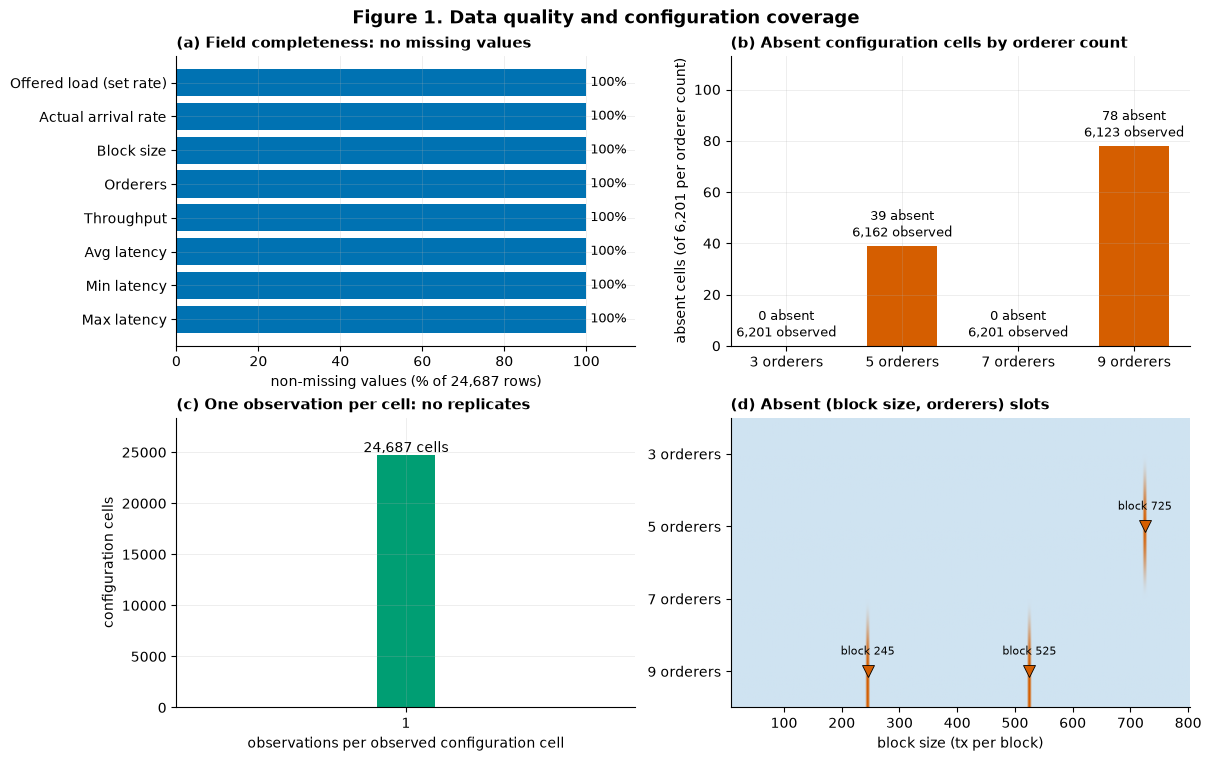

Absent (block size, orderers) slots: [(725, 5), (245, 9), (525, 9)]
Offered-load levels recorded per present (block size, orderers) slot: {39: 633} | levels in the design: 39


In [8]:
fig, axs = plt.subplots(2, 2, figsize=(12, 7.5))
fig.suptitle("Figure 1. Data quality and configuration coverage", fontsize=13, fontweight="bold")

completeness = df.notna().mean().mul(100).iloc[::-1]
axs[0, 0].barh([SHORT[c] for c in completeness.index], completeness.values, color=PALETTE["blue"])
for y, v in enumerate(completeness.values):
    axs[0, 0].text(v + 1, y, f"{v:.0f}%", va="center", fontsize=9)
axs[0, 0].set(xlim=(0, 112), xlabel=f"non-missing values (% of {len(df):,} rows)")
panel(axs[0, 0], "a", "Field completeness: no missing values")

expected_per_orderer = n_levels[SET] * n_levels[BLK]
observed = df.groupby(ORD).size()
absent = expected_per_orderer - observed
x = np.arange(len(observed))
axs[0, 1].bar(x, absent.values, color=PALETTE["red"], width=0.6)
for xi, a, o in zip(x, absent.values, observed.values):
    axs[0, 1].text(xi, a + 2, f"{a} absent\n{o:,} observed", ha="center", va="bottom", fontsize=9)
axs[0, 1].set_xticks(x, [f"{o} orderers" for o in observed.index])
axs[0, 1].set(ylim=(0, absent.max() * 1.45), ylabel=f"absent cells (of {expected_per_orderer:,} per orderer count)")
panel(axs[0, 1], "b", "Absent configuration cells by orderer count")

per_cell = cells.value_counts().sort_index()
axs[1, 0].bar(per_cell.index.astype(str), per_cell.values, color=PALETTE["green"], width=0.3)
for i, v in enumerate(per_cell.values):
    axs[1, 0].text(i, v, f"{v:,} cells", ha="center", va="bottom")
axs[1, 0].set(xlabel="observations per observed configuration cell", ylabel="configuration cells",
              xlim=(-1.2, len(per_cell) - 1 + 1.2), ylim=(0, per_cell.max() * 1.15))
panel(axs[1, 0], "c", "One observation per cell: no replicates")

slots = df.groupby([BLK, ORD])[SET].nunique().unstack(ORD)
blocks = np.sort(df[BLK].unique())
slot_map = slots.reindex(blocks).notna().T.astype(int).loc[sorted(df[ORD].unique())]
axs[1, 1].imshow(slot_map.values, aspect="auto", cmap=ListedColormap([PALETTE["red"], "#CFE3F1"]), vmin=0, vmax=1,
                 extent=[blocks.min() - 2.5, blocks.max() + 2.5, len(slot_map) - 0.5, -0.5])
axs[1, 1].grid(False)
axs[1, 1].set_yticks(range(len(slot_map)), [f"{o} orderers" for o in slot_map.index])
for o, row in zip(slot_map.index, range(len(slot_map))):
    for b in blocks[slot_map.loc[o].values == 0]:
        axs[1, 1].plot(b, row, marker="v", color=PALETTE["red"], ms=9, mec="black", mew=0.6, clip_on=False)
        axs[1, 1].annotate(f"block {int(b)}", (b, row), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8)
axs[1, 1].set(xlabel="block size (tx per block)")
panel(axs[1, 1], "d", "Absent (block size, orderers) slots")
save_figure(fig, "hfbtp_eda_01_data_quality")
absent_slots = [(int(b), int(o)) for o in slot_map.index for b in blocks[slot_map.loc[o].values == 0]]
print("Absent (block size, orderers) slots:", absent_slots)
print("Offered-load levels recorded per present (block size, orderers) slot:",
      {int(k): int(v) for k, v in slots.stack().value_counts().items()}, "| levels in the design:", n_levels[SET])

**Reading the figure.**

- **(a) No field is incomplete.** There are no missing values in any column, so there is nothing to impute.
- **(b)–(d) The only gaps are absent configurations: 117 cells, all from three (block size, orderers) slots** (block 245 and 525 at 9 orderers, block 725 at 5 orderers), each missing at *every* offered load. The gaps are therefore a fixed property of the experimental design, not load-dependent failures; why those slots were not recorded is not documented. They are never imputed.
- **(c) There are no replicates.** Every observed cell has exactly one measurement, so run-to-run variability **cannot be estimated from this file**. Differences between neighboring cells mix real configuration effects with unmeasured noise, and no confidence interval is justified.

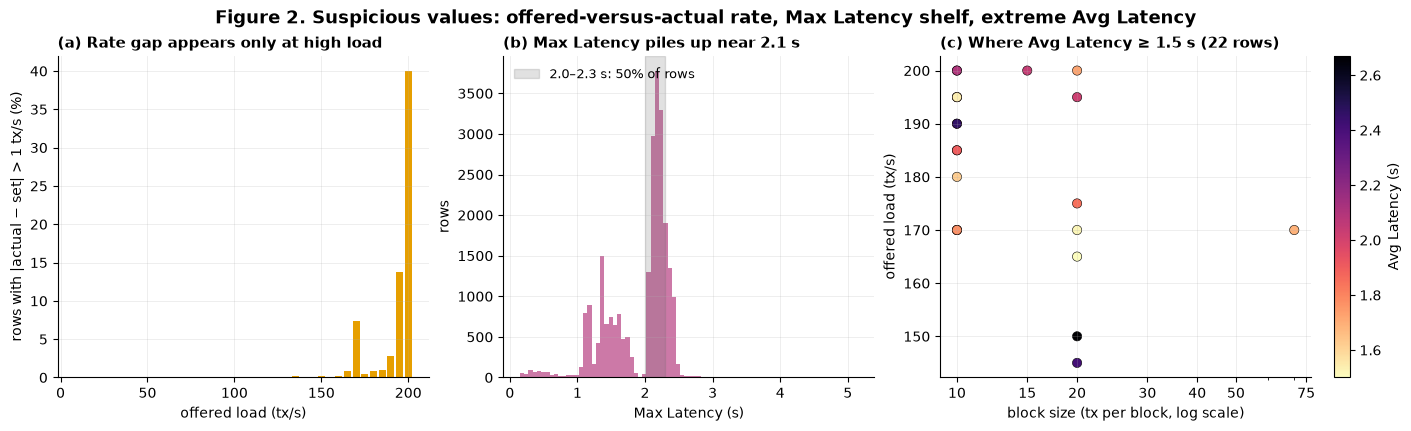

Rows with Avg Latency >= 1.5 s: 22; offered load 145-200 tx/s, block size 10-70 (21 of them at 20 or less), orderers [3, 5, 7, 9]
corr(actual rate, set rate) = 0.99995; first offered load with any |actual - set| > 1 tx/s: 135; share of rows with that gap at 170 / 195 / 200 tx/s: 7.4% / 13.7% / 40.0%
Share of rows with Max Latency in 2.0-2.3 s: 50.2%; rows with Max Latency above 3 s: 44


In [9]:
hot = df[df[LAT] >= 1.5]
shelf = df[LAT_MAX].between(2.0, 2.3).mean()

fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))
fig.suptitle("Figure 2. Suspicious values: offered-versus-actual rate, Max Latency shelf, extreme Avg Latency", fontsize=13, fontweight="bold")

gap_share = (rate_gap > 1).groupby(df[SET]).mean().mul(100)
axs[0].bar(gap_share.index, gap_share.values, width=4, color=PALETTE["orange"])
axs[0].set(xlabel="offered load (tx/s)", ylabel="rows with |actual − set| > 1 tx/s (%)")
panel(axs[0], "a", "Rate gap appears only at high load")

axs[1].hist(df[LAT_MAX], bins=80, color=PALETTE["purple"])
axs[1].axvspan(2.0, 2.3, color=PALETTE["grey"], alpha=0.2, label=f"2.0–2.3 s: {shelf:.0%} of rows")
axs[1].set(xlabel="Max Latency (s)", ylabel="rows")
axs[1].legend(loc="upper left")
panel(axs[1], "b", "Max Latency piles up near 2.1 s")

sc = axs[2].scatter(hot[BLK], hot[SET], c=hot[LAT], s=45, cmap="magma_r", edgecolor="black", linewidth=0.4)
axs[2].set(xscale="log", xlabel="block size (tx per block, log scale)", ylabel="offered load (tx/s)")
plain_log_axis(axs[2], ticks=(10, 15, 20, 30, 40, 50, 75, 100))
fig.colorbar(sc, ax=axs[2], label="Avg Latency (s)")
panel(axs[2], "c", f"Where Avg Latency ≥ 1.5 s ({len(hot)} rows)")
save_figure(fig, "hfbtp_eda_02_suspicious_values")
print(f"Rows with Avg Latency >= 1.5 s: {len(hot)}; offered load {hot[SET].min():g}-{hot[SET].max():g} tx/s, "
      f"block size {hot[BLK].min():g}-{hot[BLK].max():g} ({int((hot[BLK] <= 20).sum())} of them at 20 or less), "
      f"orderers {[int(o) for o in sorted(hot[ORD].unique())]}")
print(f"corr(actual rate, set rate) = {df[ACT].corr(df[SET]):.5f}; first offered load with any |actual - set| > 1 tx/s: "
      f"{gap_share[gap_share > 0].index.min():g}; share of rows with that gap at 170 / 195 / 200 tx/s: "
      f"{gap_share[170]:.1f}% / {gap_share[195]:.1f}% / {gap_share[200]:.1f}%")
print(f"Share of rows with Max Latency in 2.0-2.3 s: {shelf:.1%}; rows with Max Latency above 3 s: {int((df[LAT_MAX] > 3).sum())}")

**Reading the figure.**

- **Internal consistency holds.** No row has throughput above the offered load, `Min Latency` never exceeds `Avg Latency`, `Max Latency` never falls below it, and no value is zero or negative.
- **(a) The measured arrival rate follows the set rate** (correlation ≈ 1.000) and differs from it by more than 1 tx/s only from an offered load of 135 tx/s upward: in 427 rows overall, in 7.4% of the rows at 170 tx/s and in 40% of the rows at 200 tx/s. The cause is not documented. Because `Actual Transaction Arrival Rate` is measured during the run, it is excluded as a predictor by the evaluation protocol.
- **(b) Max Latency is a post-run statistic and is excluded from modeling.** Half of the rows (50.2%) have a Max Latency between 2.0 and 2.3 s, an unusually sharp concentration for a maximum; these data cannot establish why. Only the 44 rows above 3 s stand apart, and none is removed.
- **(c) The extreme Avg Latency rows sit in one corner of the design rather than being scattered.** All 22 rows at 1.5 s or more have offered loads of 145–200 tx/s and block sizes of 10–70 (21 of them at 20 or less), across all four orderer counts (the plot does not encode the orderer count, so markers overlap). This is consistent with a genuine extreme operating regime rather than isolated glitches, but with one observation per cell it cannot be checked by repetition.

## 4. Univariate distributions

The three design variables are fixed grids, so their histograms describe the experimental design, not a sampled population. The two targets are outcomes and carry the information.

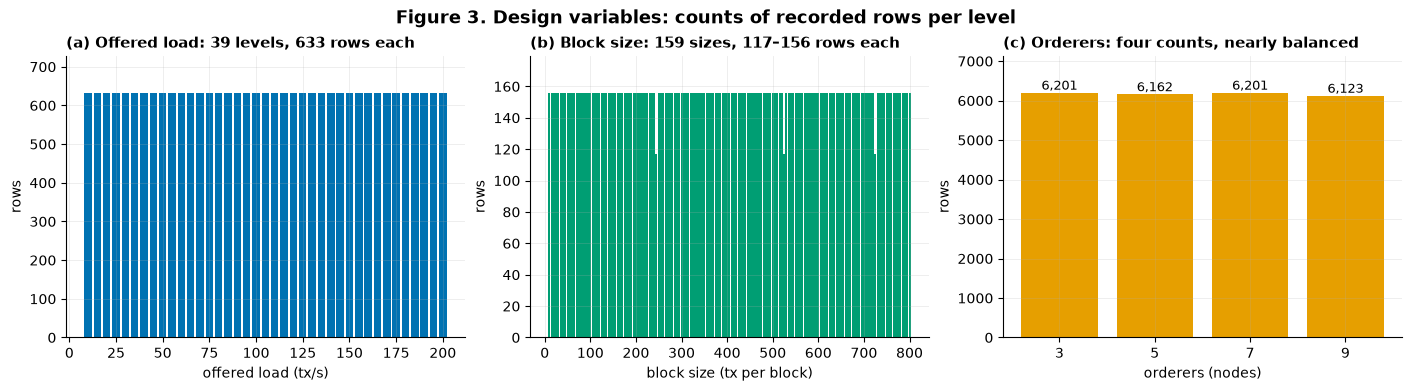

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
fig.suptitle("Figure 3. Design variables: counts of recorded rows per level", fontsize=13, fontweight="bold")

per_load = df[SET].value_counts().sort_index()
axs[0].bar(per_load.index, per_load.values, width=4, color=PALETTE["blue"])
axs[0].set(xlabel="offered load (tx/s)", ylabel="rows", ylim=(0, per_load.max() * 1.15))
panel(axs[0], "a", f"Offered load: {len(per_load)} levels, {span(per_load.min(), per_load.max())} rows each")

per_block = df[BLK].value_counts().sort_index()
axs[1].bar(per_block.index, per_block.values, width=4.5, color=PALETTE["green"])
axs[1].set(xlabel="block size (tx per block)", ylabel="rows", ylim=(0, per_block.max() * 1.15))
panel(axs[1], "b", f"Block size: {len(per_block)} sizes, {span(per_block.min(), per_block.max())} rows each")

per_orderer = df[ORD].value_counts().sort_index()
axs[2].bar(per_orderer.index.astype(str), per_orderer.values, color=PALETTE["orange"])
for i, v in enumerate(per_orderer.values):
    axs[2].text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
axs[2].set(xlabel="orderers (nodes)", ylabel="rows", ylim=(0, per_orderer.max() * 1.15))
panel(axs[2], "c", "Orderers: four counts, nearly balanced")
save_figure(fig, "hfbtp_eda_03_design_variables")

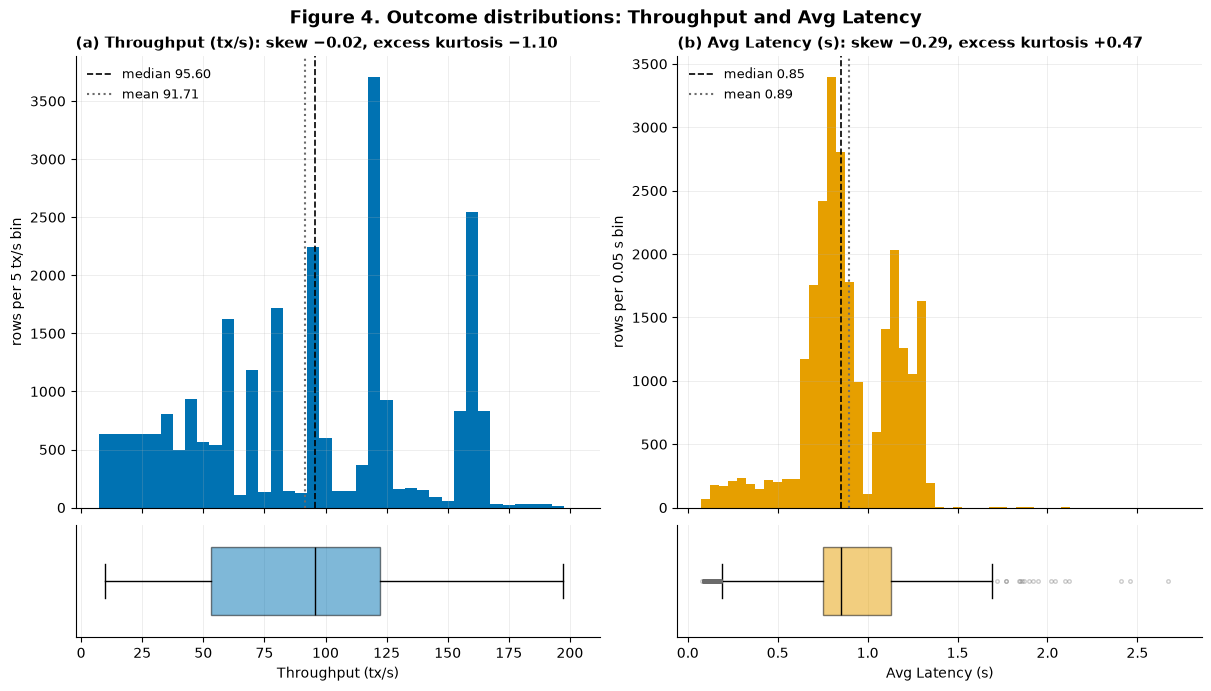

Rows contributed by one offered-load level: 633 (2.6% of all rows)
Throughput: bins of width 5 tx/s holding at least 5% of all rows and more than both neighbours (bin center, rows, share): [(60.0, 1627, '6.6%'), (80.0, 1722, '7.0%'), (95.0, 2244, '9.1%'), (120.0, 3703, '15.0%'), (160.0, 2546, '10.3%')]
Avg Latency: bins of width 0.05 s holding at least 5% of all rows and more than both neighbours (bin center, rows, share): [(0.8, 3393, '13.7%'), (1.15, 2029, '8.2%'), (1.3, 1629, '6.6%')]


In [11]:
# Bin edges are aligned with the resolution of each variable (5 tx/s load grid; 0.01 s latency resolution) so that
# the bin counts do not alias against the design grid.
HIST_BINS = {TPUT: np.arange(7.5, 202.6, 5.0), LAT: np.arange(0.075, 2.73, 0.05)}
BIN_WIDTH = {TPUT: 5, LAT: 0.05}


def signed(number):
    return f"{number:+.2f}".replace("-", "−")


fig, axs = plt.subplots(2, 2, figsize=(12, 6.8), gridspec_kw={"height_ratios": [4, 1]}, sharex="col")
fig.suptitle("Figure 4. Outcome distributions: Throughput and Avg Latency", fontsize=13, fontweight="bold")
for col, (target, color) in enumerate(((TPUT, PALETTE["blue"]), (LAT, PALETTE["orange"]))):
    values = df[target]
    axs[0, col].hist(values, bins=HIST_BINS[target], color=color)
    axs[0, col].axvline(values.median(), color="black", ls="--", lw=1.2, label=f"median {values.median():.2f}")
    axs[0, col].axvline(values.mean(), color=PALETTE["grey"], ls=":", lw=1.5, label=f"mean {values.mean():.2f}")
    axs[0, col].set(ylabel=f"rows per {BIN_WIDTH[target]:g} {UNIT[target]} bin")
    axs[0, col].legend(loc="upper left")
    panel(axs[0, col], "ab"[col], f"{target} ({UNIT[target]}): skew {signed(values.skew())}, excess kurtosis {signed(values.kurt())}")
    axs[1, col].boxplot(values, widths=0.6, patch_artist=True, boxprops={"facecolor": color, "alpha": 0.5},
                        medianprops={"color": "black"}, whis=1.5,
                        flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": "none", "markeredgecolor": PALETTE["grey"],
                                    "alpha": 0.35}, **BOX_HORIZONTAL)
    axs[1, col].set(xlabel=f"{target} ({UNIT[target]})", yticks=[])
save_figure(fig, "hfbtp_eda_04_outcome_distributions")

print(f"Rows contributed by one offered-load level: {int(df[SET].value_counts().iloc[0])} ({df[SET].value_counts().iloc[0] / len(df):.1%} of all rows)")
for target in (TPUT, LAT):
    counts, edges = np.histogram(df[target], bins=HIST_BINS[target])
    centers = (edges[:-1] + edges[1:]) / 2
    peaks = [(round(float(c), 2), int(n), f"{n / len(df):.1%}") for i, (c, n) in enumerate(zip(centers, counts))
             if 0 < i < len(counts) - 1 and n > counts[i - 1] and n > counts[i + 1] and n >= 0.05 * len(df)]
    print(f"{target}: bins of width {BIN_WIDTH[target]:g} {UNIT[target]} holding at least 5% of all rows and more than both neighbours "
          f"(bin center, rows, share): {peaks}")

In [12]:
describe_cols = [SET, BLK, ORD, TPUT, LAT]
q1, q3 = df[describe_cols].quantile(0.25), df[describe_cols].quantile(0.75)
fence_lo, fence_hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
distribution = pd.DataFrame({
    "mean": df[describe_cols].mean(), "std": df[describe_cols].std(), "min": df[describe_cols].min(),
    "25%": q1, "median": df[describe_cols].median(), "75%": q3, "max": df[describe_cols].max(),
    "skew": df[describe_cols].skew(), "excess kurtosis": df[describe_cols].kurt(),
    "below 1.5×IQR fence": (df[describe_cols] < fence_lo).sum(), "above 1.5×IQR fence": (df[describe_cols] > fence_hi).sum(),
})
distribution.index = [SHORT[c] for c in distribution.index]

for side, mask, fence in (("below", df[LAT] < fence_lo[LAT], fence_lo[LAT]), ("above", df[LAT] > fence_hi[LAT], fence_hi[LAT])):
    flagged = df[mask]
    print(f"Avg Latency {side} its 1.5×IQR fence ({fence:.2f} s): {len(flagged)} rows; block sizes {flagged[BLK].min():g}-{flagged[BLK].max():g}, "
          f"offered loads {flagged[SET].min():g}-{flagged[SET].max():g} tx/s")
distribution

Avg Latency below its 1.5×IQR fence (0.18 s): 285 rows; block sizes 10-25, offered loads 35-195 tx/s
Avg Latency above its 1.5×IQR fence (1.70 s): 17 rows; block sizes 10-20, offered loads 145-200 tx/s


,mean,std,min,25%,median,75%,max,skew,excess kurtosis,below 1.5×IQR fence,above 1.5×IQR fence
Offered load (set rate),105.000,56.274,10.00,55.00,105.00,155.00,200.00,0.000,-1.202,0,0
Block size,404.558,229.550,10.00,205.00,405.00,605.00,800.00,0.002,-1.200,0,0
Orderers,5.992,2.235,3.00,3.00,5.00,7.00,9.00,0.003,-1.358,0,0
Throughput,91.712,46.632,9.80,53.00,95.60,122.20,197.30,-0.015,-1.097,0,0
Avg latency,0.895,0.256,0.08,0.75,0.85,1.13,2.67,-0.286,0.469,285,17


**Reading the figures and table.**

- **Design variables are flat by construction** (excess kurtosis −1.20 for load and block size, the value for a uniform distribution; −1.36 for four equally spaced orderer counts). The only visible departures are the three dips from the absent block-size slots and the slightly smaller 5- and 9-orderer groups.
- **Throughput is multimodal, not bell-shaped.** With 5 tx/s bins aligned to the load grid, the three tallest concentrations are near 120, 160 and 95 tx/s, holding 15%, 10% and 9% of all rows, whereas one offered-load level contributes only 2.6%; shorter concentrations sit near 60 and 80 tx/s. These are the stepwise throughput levels that Section 5 traces to the offered load. The near-zero skew (−0.015) and the absence of IQR-fence outliers show only that the pile-ups balance each other; they do not describe one symmetric population.
- **Avg Latency has two main concentrations**: a tall one near 0.8 s and a broader one between roughly 1.1 and 1.35 s (peaks at 1.15 and 1.30 s), with a low-density tail of fast rows below 0.6 s. The IQR fences flag 285 low values (below 0.18 s) and 17 high values (above 1.70 s); **every flagged row, on both sides, has a block size of 25 or less**, so both tails belong to the smallest block sizes (Section 6).
- **Neither target is strongly skewed, so the marginal shapes give no case for a log transform.** Axes are in raw units; later plots use a log *axis* for block size only to resolve its 10–50 range. The repository's eight-feature model includes log10 inputs by design (its feature specification was fixed before this EDA and is not chosen from it), whereas the frozen three-feature baseline uses raw inputs.

## 5. Workload–performance relationships

How do the two outcomes respond to the offered load? Each point below is one configuration (a block size and an orderer count at one load); the line and band summarize the spread *across* configurations at each load, not measurement noise.

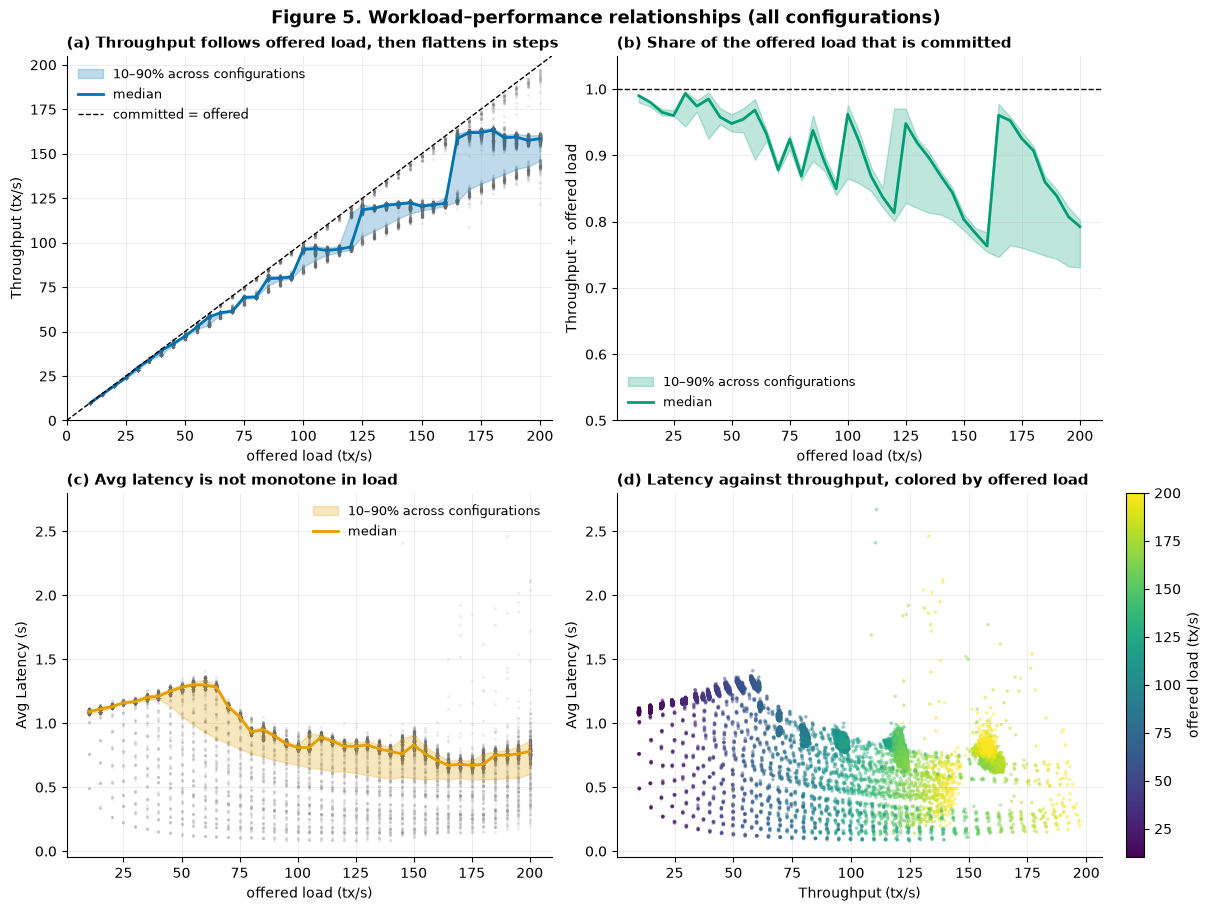

Median committed share first falls below 95% at an offered load of 50 tx/s
Median committed share at 95 / 100 / 120 / 125 / 160 / 165 / 200 tx/s: [0.849, 0.962, 0.813, 0.948, 0.763, 0.961, 0.792]
Median throughput (tx/s) at 100 / 120 / 130 / 160 / 165 / 180 / 200 tx/s offered: [96.2, 97.6, 119.4, 122.1, 158.5, 163.3, 158.5]
Median Avg Latency (s): 1.09 at 10 tx/s, peak 1.30 at 55 tx/s, 0.81 at 100 tx/s, 0.78 at 200 tx/s


In [13]:
tput_q = df.groupby(SET)[TPUT].quantile([0.1, 0.5, 0.9]).unstack()
lat_q = df.groupby(SET)[LAT].quantile([0.1, 0.5, 0.9]).unstack()
eff_q = (df[TPUT] / df[SET]).groupby(df[SET]).quantile([0.1, 0.5, 0.9]).unstack()

fig, axs = plt.subplots(2, 2, figsize=(12, 9))
fig.suptitle("Figure 5. Workload–performance relationships (all configurations)", fontsize=13, fontweight="bold")


def load_curve(ax, q, color, label):
    ax.fill_between(q.index, q[0.1], q[0.9], color=color, alpha=0.25, label="10–90% across configurations")
    ax.plot(q.index, q[0.5], color=color, lw=2, label=label)


axs[0, 0].scatter(df[SET], df[TPUT], s=2, alpha=0.08, color=PALETTE["grey"], rasterized=True)
load_curve(axs[0, 0], tput_q, PALETTE["blue"], "median")
axs[0, 0].plot([0, 205], [0, 205], "k--", lw=1, label="committed = offered")
axs[0, 0].set(xlabel="offered load (tx/s)", ylabel="Throughput (tx/s)", xlim=(0, 205), ylim=(0, 205))
axs[0, 0].legend(loc="upper left")
panel(axs[0, 0], "a", "Throughput follows offered load, then flattens in steps")

load_curve(axs[0, 1], eff_q, PALETTE["green"], "median")
axs[0, 1].axhline(1.0, color="black", ls="--", lw=1)
axs[0, 1].set(xlabel="offered load (tx/s)", ylabel="Throughput ÷ offered load", ylim=(0.5, 1.05))
axs[0, 1].legend(loc="lower left")
panel(axs[0, 1], "b", "Share of the offered load that is committed")

axs[1, 0].scatter(df[SET], df[LAT], s=2, alpha=0.08, color=PALETTE["grey"], rasterized=True)
load_curve(axs[1, 0], lat_q, PALETTE["orange"], "median")
axs[1, 0].set(xlabel="offered load (tx/s)", ylabel="Avg Latency (s)")
axs[1, 0].legend(loc="upper right")
panel(axs[1, 0], "c", "Avg latency is not monotone in load")

sc = axs[1, 1].scatter(df[TPUT], df[LAT], c=df[SET], s=3, alpha=0.35, cmap="viridis", rasterized=True)
fig.colorbar(plt.cm.ScalarMappable(norm=sc.norm, cmap=sc.cmap), ax=axs[1, 1], label="offered load (tx/s)")
axs[1, 1].set(xlabel="Throughput (tx/s)", ylabel="Avg Latency (s)")
panel(axs[1, 1], "d", "Latency against throughput, colored by offered load")
save_figure(fig, "hfbtp_eda_05_workload_performance")

median_latency, median_share = lat_q[0.5], eff_q[0.5]
print(f"Median committed share first falls below 95% at an offered load of {median_share[median_share < 0.95].index.min():g} tx/s")
print("Median committed share at 95 / 100 / 120 / 125 / 160 / 165 / 200 tx/s:",
      [round(float(median_share.loc[v]), 3) for v in (95, 100, 120, 125, 160, 165, 200)])
print("Median throughput (tx/s) at 100 / 120 / 130 / 160 / 165 / 180 / 200 tx/s offered:",
      [round(float(tput_q.loc[v, 0.5]), 1) for v in (100, 120, 130, 160, 165, 180, 200)])
print(f"Median Avg Latency (s): {median_latency.loc[10]:.2f} at 10 tx/s, peak {median_latency.max():.2f} at {median_latency.idxmax():g} tx/s, "
      f"{median_latency.loc[100]:.2f} at 100 tx/s, {median_latency.loc[200]:.2f} at 200 tx/s")

**Reading the figure.**

- **(a)–(b) Throughput keeps up with the offered load only at the lowest loads, then flattens in steps.** The median committed share first falls below 95% at 50 tx/s (printed above), and the median throughput curve is a *staircase* of ceilings rather than a smooth saturation curve: it levels off near 96 tx/s (offered loads of roughly 100–120), steps up to about 120 tx/s (roughly 125–160) and again to about 160 tx/s (roughly 165–200). Because throughput stays constant within a step while the offered load keeps rising, the committed share in (b) falls along each step and jumps back up where the next ceiling begins, a *sawtooth*. The band shows that, at a given load, different block-size and orderer settings commit noticeably different throughput once the system is loaded.
- **(c) Latency is not monotone in load.** The median Avg Latency rises from about 1.1 s at 10 tx/s to a peak of about 1.3 s near 55 tx/s and then falls to between roughly 0.7 and 0.8 s over the highest loads. This is the opposite of the usual queueing expectation; these data describe the pattern but cannot explain it.
- **(d) Latency and throughput are negatively associated across the grid (Pearson −0.67, Spearman −0.78, Section 7), but not along a single curve.** Below roughly 60 tx/s latency *rises* with throughput; beyond that it falls, and each offered load forms its own cluster. Offered load drives both, so the plot is not evidence that raising throughput lowers latency.

## 6. Configuration interactions

Offered load is exogenous; block size and orderer count are the configuration knobs a controller could change. The question is whether their effect is the same at every load. If it is not, a model that adds one effect per variable cannot represent the surface.

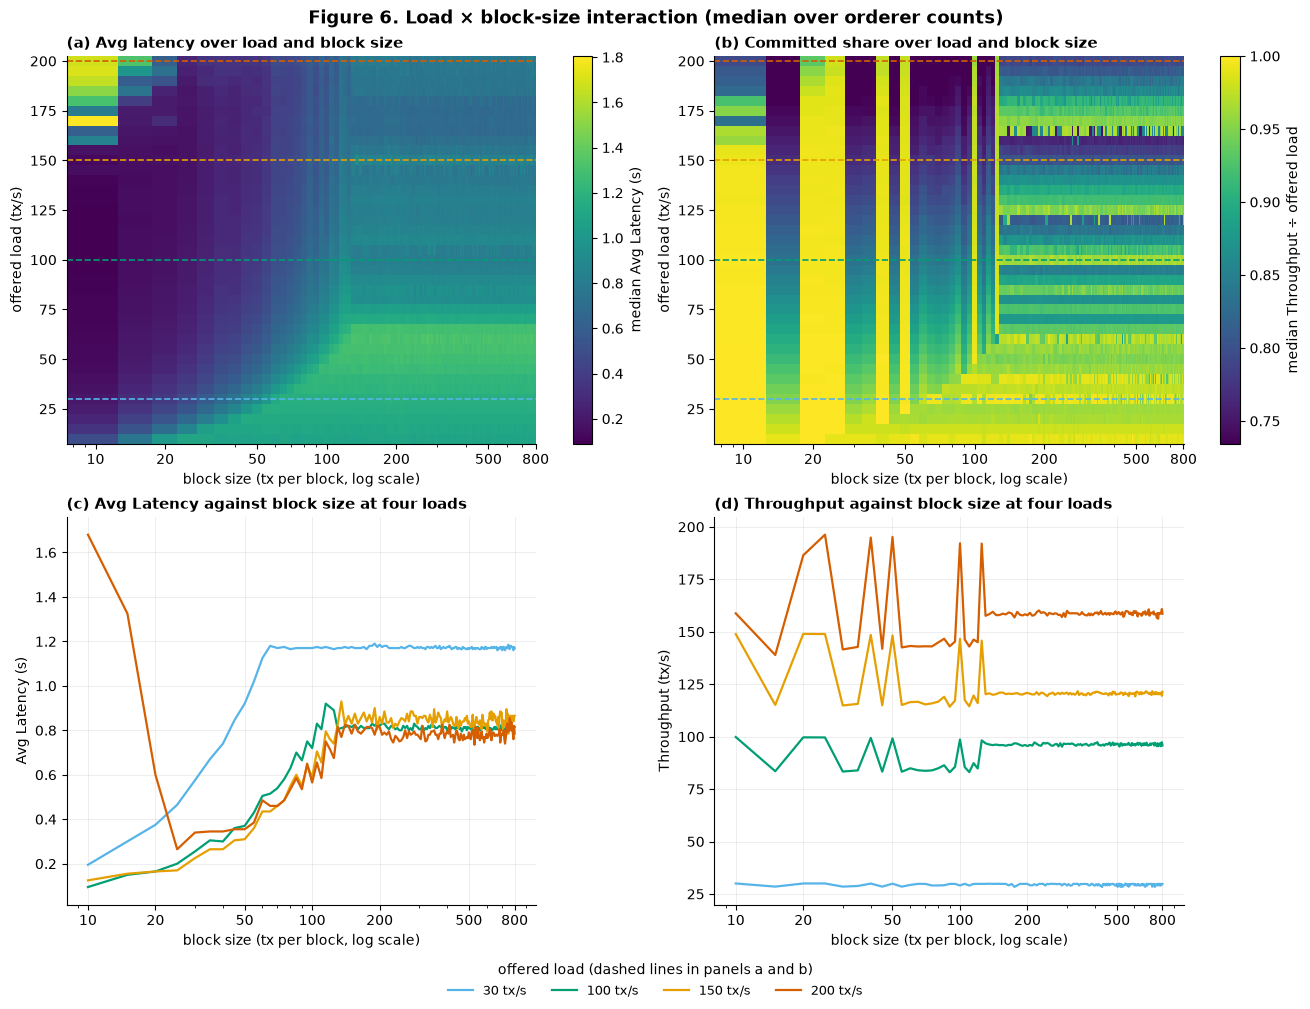

100 tx/s: block sizes of at most 130 whose median throughput is at least 95% of the load: [10, 20, 25, 40, 50, 100, 125, 130]
150 tx/s: block sizes of at most 130 whose median throughput is at least 95% of the load: [10, 20, 25, 40, 50, 100, 125]
200 tx/s: block sizes of at most 130 whose median throughput is at least 95% of the load: [25, 40, 50, 100, 125]


,30 tx/s,100 tx/s,150 tx/s,200 tx/s
Avg latency at block 10 (s),0.20,0.10,0.12,1.68
Avg latency at block 50 (s),0.92,0.37,0.31,0.35
Avg latency at block 800 (s),1.17,0.81,0.86,0.79
lowest Avg latency (s) and its block size,0.20 at 10,0.10 at 10,0.12 at 10,0.27 at 25
latency plateau (s),1.17,0.81,0.84,0.78
latency within ±0.12 s of it from block size,60,95,115,115
throughput plateau (tx/s),29.7,96.3,120.6,158.8
throughput within ±5 tx/s of it from block size,10,125,130,130
range of throughput across block sizes (tx/s),1.7,16.8,34.7,57.3
blocks ≤ 130 committing ≥ 95% of the load,25 of 25,8 of 25,7 of 25,5 of 25


In [14]:
surface = df.groupby([SET, BLK])[[TPUT, LAT]].median().reset_index()
surface["efficiency"] = surface[TPUT] / surface[SET]
lat_surface = surface.pivot(index=SET, columns=BLK, values=LAT)
eff_surface = surface.pivot(index=SET, columns=BLK, values="efficiency")
LINE_LOADS = (30, 100, 150, 200)
LOAD_COLORS = dict(zip(LINE_LOADS, (PALETTE["sky"], PALETTE["green"], PALETTE["orange"], PALETTE["red"])))

fig, axs = plt.subplots(2, 2, figsize=(13, 10))
fig.suptitle("Figure 6. Load × block-size interaction (median over orderer counts)", fontsize=13, fontweight="bold")

for ax, grid_values, label, vmin, vmax, letter, title in (
        (axs[0, 0], lat_surface, "median Avg Latency (s)", None, None, "a", "Avg latency over load and block size"),
        (axs[0, 1], eff_surface, "median Throughput ÷ offered load", np.nanpercentile(eff_surface.values, 1), 1.0, "b",
         "Committed share over load and block size")):
    X, Y = np.meshgrid(grid_values.columns.values, grid_values.index.values)
    mesh = ax.pcolormesh(X, Y, grid_values.values, shading="auto", vmin=vmin, vmax=vmax, rasterized=True)
    ax.set(xscale="log", xlabel="block size (tx per block, log scale)", ylabel="offered load (tx/s)")
    plain_log_axis(ax)
    ax.grid(False)
    for load in LINE_LOADS:
        ax.axhline(load, color=LOAD_COLORS[load], lw=1.2, ls="--")
    fig.colorbar(mesh, ax=ax, label=label)
    panel(ax, letter, title)

for ax, target, letter in ((axs[1, 0], LAT, "c"), (axs[1, 1], TPUT, "d")):
    for load in LINE_LOADS:
        line = surface[surface[SET] == load]
        ax.plot(line[BLK], line[target], color=LOAD_COLORS[load], lw=1.6, label=f"{load} tx/s")
    ax.set(xscale="log", xlabel="block size (tx per block, log scale)", ylabel=f"{target} ({UNIT[target]})")
    plain_log_axis(ax)
    panel(ax, letter, f"{target} against block size at four loads")
handles, labels = axs[1, 0].get_legend_handles_labels()
fig.legend(handles, labels, title="offered load (dashed lines in panels a and b)", loc="outside lower center", ncol=4)
save_figure(fig, "hfbtp_eda_06_load_block_interaction")


def plateau_start(series, tolerance, plateau_from=300):
    """Smallest block size from which every larger block stays within +/- tolerance of the large-block plateau."""
    plateau = series[series.index >= plateau_from].median()
    inside = ((series - plateau).abs() <= tolerance).iloc[::-1].astype(int).cummin().iloc[::-1].astype(bool)
    return plateau, inside[inside].index.min()


rows = {}
for load in LINE_LOADS:
    line = surface[surface[SET] == load].set_index(BLK)
    lat_plateau, lat_from = plateau_start(line[LAT], 0.12)
    tput_plateau, tput_from = plateau_start(line[TPUT], 5.0)
    small = line.loc[line.index <= 130]
    sustained = int((small[TPUT] >= 0.95 * load).sum())
    if load > 30:
        print(f"{load} tx/s: block sizes of at most 130 whose median throughput is at least 95% of the load: "
              f"{[int(b) for b in small.index[small[TPUT] >= 0.95 * load]]}")
    rows[f"{load} tx/s"] = {
        "Avg latency at block 10 (s)": f"{line.loc[10, LAT]:.2f}", "Avg latency at block 50 (s)": f"{line.loc[50, LAT]:.2f}",
        "Avg latency at block 800 (s)": f"{line.loc[800, LAT]:.2f}",
        "lowest Avg latency (s) and its block size": f"{line[LAT].min():.2f} at {int(line[LAT].idxmin())}",
        "latency plateau (s)": f"{lat_plateau:.2f}", "latency within ±0.12 s of it from block size": int(lat_from),
        "throughput plateau (tx/s)": f"{tput_plateau:.1f}", "throughput within ±5 tx/s of it from block size": int(tput_from),
        "range of throughput across block sizes (tx/s)": f"{line[TPUT].max() - line[TPUT].min():.1f}",
        "blocks ≤ 130 committing ≥ 95% of the load": f"{sustained} of {len(small)}"}
interaction_table = pd.DataFrame(rows)
interaction_table

**Reading the figure.**

Values below are read from the table above (medians over the four orderer counts).

- **(a), (c) The effect of block size on latency depends on the load.** At 100 and 150 tx/s the smallest blocks are the *fastest* (0.10 and 0.12 s at block 10) and latency climbs with block size to a plateau of about 0.8 s that is reached near block size 95–115. At 30 tx/s the climb is slower (0.20 s at block 10, a plateau of 1.17 s from about block 60). At 200 tx/s the smallest blocks are the *slowest*: 1.68 s at block 10, falling steeply to 0.27 s at block 25 before rising to a plateau of 0.78 s. So the direction of the block-size effect at the smallest sizes differs between 150 and 200 tx/s, and the plateau level itself is not a monotone function of load (1.17, 0.81, 0.84, 0.78 s).
- **(b), (d) Throughput hardly depends on block size at 30 tx/s but strongly at high load.** At 30 tx/s it varies by 1.7 tx/s across block sizes; at 100, 150 and 200 tx/s by 17, 35 and 57 tx/s. From about block size 130 upward throughput sits on a flat plateau (about 96, 121 and 159 tx/s). Below that the curve is irregular: only 8, 7 and 5 of the 25 block sizes of at most 130 commit at least 95% of the load at 100, 150 and 200 tx/s, they do not form a contiguous range (the lists are printed above), and neighboring sizes can differ by tens of tx/s. With one observation per cell, whether this irregularity is systematic or run-to-run variation **cannot be established from the current evidence**.
- A model that gives block size one slope at every load cannot represent either pattern. The eight-feature variant adds a Block/Set ratio and log terms but not a free load × block-size interaction; Section 8 shows how far that gets.

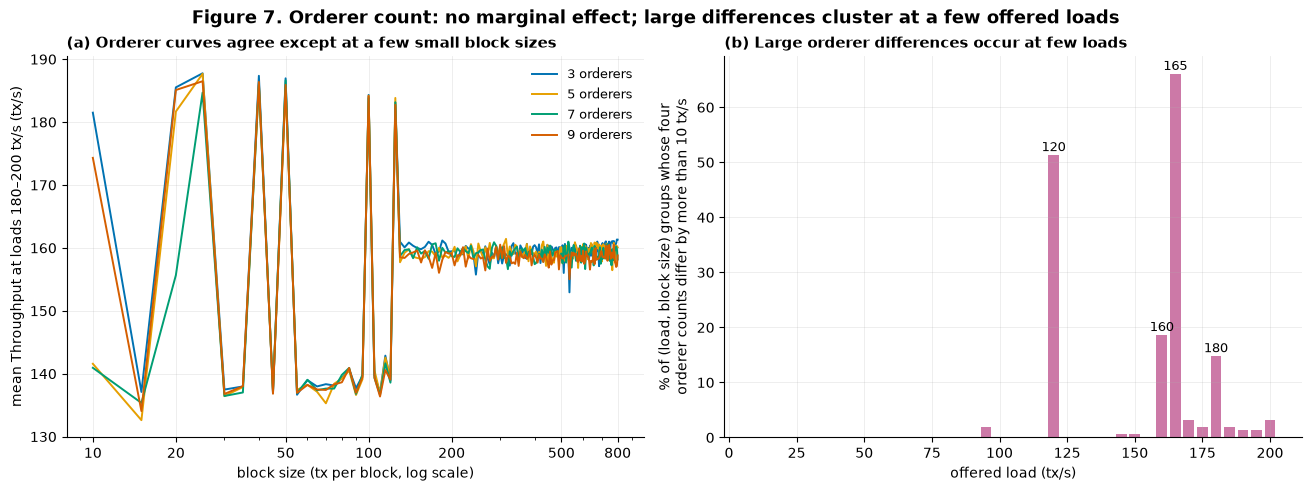

Mean Throughput by orderers (tx/s): {3: 91.88, 5: 91.67, 7: 91.7, 9: 91.6}
Mean Avg Latency by orderers (s): {3: 0.883, 5: 0.893, 7: 0.899, 9: 0.903}
Avg Latency standard deviation: 0.256 s
Median spread between orderer counts, by offered-load band (tx/s): {'10–55': 0.3, '60–145': 1.3, '150–160': 1.8, '165–200': 3.5}
Share of groups with a spread above 10 tx/s (%), by band: {'10–55': 0.0, '60–145': 3.0, '150–160': 6.4, '165–200': 11.7} | maximum spread (tx/s): 57.9
Groups with a spread above 10 tx/s: 260 of 6,084; 235 of them (90%) lie on the four offered loads below, and no other load has more than 5.
Orderer count that departs most from its group's median throughput, among those groups:


,groups > 10 tx/s,departing count above the others,3 orderers,5 orderers,7 orderers,9 orderers
120 tx/s,80,68,5,7,26,42
160 tx/s,29,28,1,4,11,13
165 tx/s,103,50,28,27,24,24
180 tx/s,23,4,2,3,8,10


In [15]:
heavy_load = df[df[SET] >= 180]
by_block = heavy_load.groupby([BLK, ORD])[TPUT].mean().unstack(ORD)

LARGE_SPREAD = 10  # tx/s; a descriptive threshold, not an estimated noise level (there are no replicates)
complete = df.pivot_table(index=[SET, BLK], columns=ORD, values=TPUT).dropna()
group_spread = complete.max(axis=1) - complete.min(axis=1)
share_large = (group_spread > LARGE_SPREAD).groupby(level=0).mean().mul(100)
BANDS = (("10–55", 0, 55), ("60–145", 55, 145), ("150–160", 145, 160), ("165–200", 160, 205))
band_spread = {name: group_spread[(group_spread.index.get_level_values(0) > lo) & (group_spread.index.get_level_values(0) <= hi)]
               for name, lo, hi in BANDS}

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
fig.suptitle("Figure 7. Orderer count: no marginal effect; large differences cluster at a few offered loads", fontsize=13, fontweight="bold")
for o in sorted(df[ORD].unique()):
    axs[0].plot(by_block.index, by_block[o], color=ORDERER_COLORS[o], lw=1.4, label=f"{o} orderers")
axs[0].set(xscale="log", xlabel="block size (tx per block, log scale)", ylabel="mean Throughput at loads 180–200 tx/s (tx/s)")
plain_log_axis(axs[0])
axs[0].legend()
panel(axs[0], "a", "Orderer curves agree except at a few small block sizes")

axs[1].bar(share_large.index, share_large.values, width=4, color=PALETTE["purple"])
for load, share in share_large[share_large > 10].items():
    axs[1].annotate(f"{load:g}", (load, share), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
axs[1].set(xlabel="offered load (tx/s)", ylabel=f"% of (load, block size) groups whose four\norderer counts differ by more than {LARGE_SPREAD} tx/s")
panel(axs[1], "b", "Large orderer differences occur at few loads")
save_figure(fig, "hfbtp_eda_07_orderer_effect")

print("Mean Throughput by orderers (tx/s):", {int(k): float(v) for k, v in df.groupby(ORD)[TPUT].mean().round(2).items()})
print("Mean Avg Latency by orderers (s):", {int(k): float(v) for k, v in df.groupby(ORD)[LAT].mean().round(3).items()})
print(f"Avg Latency standard deviation: {df[LAT].std():.3f} s")
print("Median spread between orderer counts, by offered-load band (tx/s):", {name: round(float(s.median()), 2) for name, s in band_spread.items()})
print(f"Share of groups with a spread above {LARGE_SPREAD} tx/s (%), by band:", {name: round(float((s > LARGE_SPREAD).mean() * 100), 1) for name, s in band_spread.items()},
      "| maximum spread (tx/s):", round(float(group_spread.max()), 1))

large = complete[group_spread > LARGE_SPREAD]
departing = large.sub(large.median(axis=1), axis=0).abs().idxmax(axis=1)    # orderer count farthest from its group's median
departs_upward = (large.max(axis=1) - large.median(axis=1)) >= (large.median(axis=1) - large.min(axis=1))
groups_by_load = departing.groupby(level=0).size().sort_values(ascending=False)
top_loads = sorted(groups_by_load.head(4).index)
top_total = int(groups_by_load.loc[top_loads].sum())
print(f"Groups with a spread above {LARGE_SPREAD} tx/s: {len(large)} of {len(complete):,}; {top_total} of them ({top_total / len(large):.0%}) lie on the four "
      f"offered loads below, and no other load has more than {int(groups_by_load.drop(top_loads).max())}.")
print("Orderer count that departs most from its group's median throughput, among those groups:")
departures = pd.crosstab(departing.index.get_level_values(0), departing.to_numpy()).loc[top_loads]
departures.columns = [f"{int(o)} orderers" for o in departures.columns]
departures.insert(0, "groups > 10 tx/s", groups_by_load.loc[top_loads])
departures.insert(1, "departing count above the others", departs_upward.groupby(level=0).sum().loc[top_loads].astype(int))
departures.index = [f"{load:g} tx/s" for load in departures.index]
departures

**Reading the figure.**

- **The orderer count has almost no marginal effect.** Mean throughput is 91.6–91.9 tx/s and mean Avg Latency 0.88–0.90 s for 3, 5, 7 and 9 orderers (printed above), so a global orderer coefficient is close to zero. The latency means rise monotonically with the orderer count (0.883 to 0.903 s); against a standard deviation of 0.26 s that is small, and with one observation per cell its reliability cannot be judged.
- **Where orderer counts differ, they differ at a few loads.** For most (load, block size) groups the four counts agree closely: the median spread is 0.3 tx/s up to 55 tx/s and 3.5 tx/s from 165 tx/s, and in panel (a) the four curves coincide at heavy load except at a few small block sizes (10, 20, 25). Only 260 of the 6,084 complete groups differ by more than 10 tx/s (up to 58 tx/s), and about 90% of those lie on four offered loads (120, 160, 165 and 180 tx/s; panel b), which sit next to the steps of the throughput staircase in Section 5.
- **This pattern does not identify an orderer effect.** At 165 tx/s the orderer count that departs most from its group is spread evenly over 3, 5, 7 and 9 (and lies above the group about as often as below it), whereas at 120 and 160 tx/s it is mostly 7 or 9 and usually lies above the other three; at 180 tx/s it is again mostly 7 or 9 but lies *below* the others in 19 of 23 groups (table above), so even the direction is not consistent. A run that lands just before or just after a step may partly be chance, so a load-conditional orderer effect and run-to-run variation **cannot be told apart from the current evidence**; the same holds for every spread in this figure, because each group has one measurement per orderer count.

## 7. Correlation and feature relationships

Pearson correlation measures *linear* association and Spearman correlation measures *monotone* association. Both are shown for the three design inputs and the two targets.

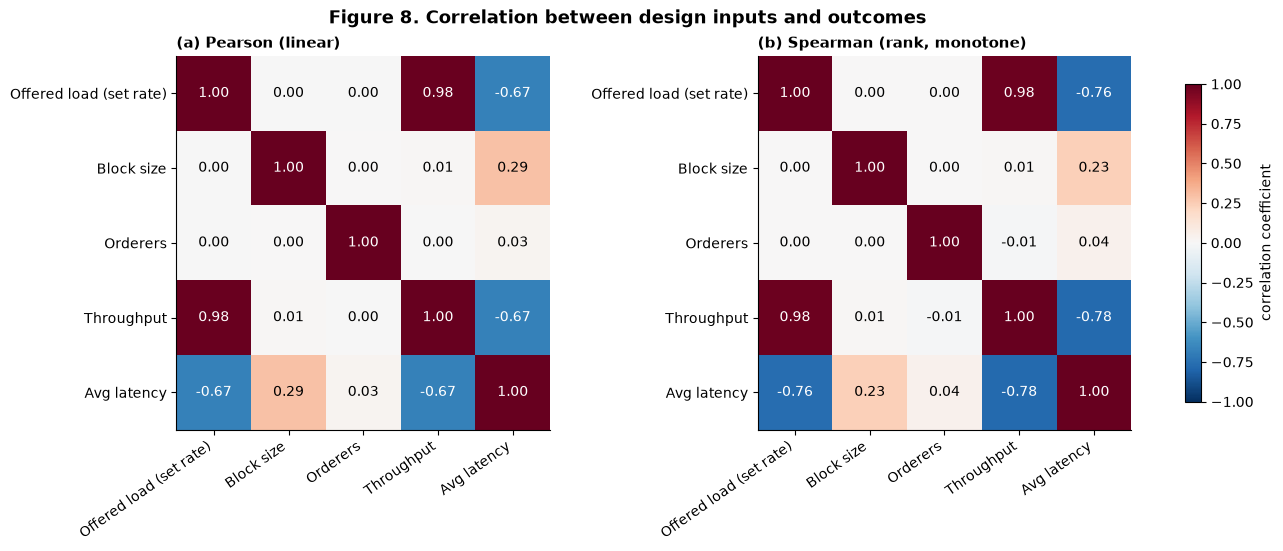

corr(actual rate, set rate) = 0.99995; corr(actual rate, Throughput) = 0.985


In [16]:
CORR_COLS = [SET, BLK, ORD, TPUT, LAT]
correlations = {"Pearson (linear)": df[CORR_COLS].corr(), "Spearman (rank, monotone)": df[CORR_COLS].corr(method="spearman")}

fig, axs = plt.subplots(1, 2, figsize=(13, 5.4))
fig.suptitle("Figure 8. Correlation between design inputs and outcomes", fontsize=13, fontweight="bold")
for ax, letter, (name, cm) in zip(axs, "ab", correlations.items()):
    image = ax.imshow(cm.values, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(CORR_COLS)), [SHORT[c] for c in CORR_COLS], rotation=35, ha="right")
    ax.set_yticks(range(len(CORR_COLS)), [SHORT[c] for c in CORR_COLS])
    ax.grid(False)
    for i in range(len(CORR_COLS)):
        for j in range(len(CORR_COLS)):
            ax.text(j, i, f"{cm.values[i, j] + 0.0:.2f}".replace("-0.00", "0.00"), ha="center", va="center", fontsize=10,
                    color="white" if abs(cm.values[i, j]) > 0.6 else "black")
    panel(ax, letter, name)
fig.colorbar(image, ax=axs, shrink=0.85, label="correlation coefficient")
save_figure(fig, "hfbtp_eda_08_correlation")

print(f"corr(actual rate, set rate) = {df[ACT].corr(df[SET]):.5f}; corr(actual rate, Throughput) = {df[ACT].corr(df[TPUT]):.3f}")

**Reading the figure, and its limits.**

- **Throughput is almost perfectly correlated with offered load** (0.98, both coefficients) because the system commits what it is offered up to its first ceiling. That relationship reflects the *workload*, not a property of the configuration, and it is why R² is an inflated measure of skill on this dataset: even a trivial model of offered load scores highly.
- **Block size and orderers show essentially no correlation with throughput** (about 0.01 or less in absolute value), yet Section 6 shows that block size changes throughput by tens of tx/s under heavy load. Correlation averages over loads, so it **cannot** reveal an effect whose size or direction depends on load. Near-zero correlation does not mean "irrelevant".
- **Latency is moderately negatively correlated with load (−0.67 Pearson, −0.76 Spearman) and weakly positively with block size (0.29, 0.23).** A single coefficient cannot summarize the rise-then-fall of latency in load (Figure 5c), and the latency–throughput coefficient (−0.67, −0.78) mostly reflects that both follow load.
- **Correlation is not causation, and it does not select features.** The registered feature set is fixed by the protocol; this heatmap neither adds nor removes a predictor. `Actual Transaction Arrival Rate` is excluded because it is measured during the run (its correlation with the set rate is ≈ 1.000 and with Throughput 0.985), not because of any coefficient shown here.

## 8. Evidence of nonlinear behavior: where Multiple Linear Regression helps and where it fails

Multiple linear regression (ordinary least squares on several predictors) is the interpretable reference of the modeling ladder: it is fast, has no tuning knobs, and its coefficients describe the *first-order, additive* association between each input and each target. That is what makes it informative here, and also why it can be insufficient: if the response depends on interactions (load × block size) and thresholds (saturation), a first-order model leaves *structured* residuals.

Two specifications exist in this project. They are different models and are kept apart:

| Label | Predictors | Estimator | Status |
|---|---|---|---|
| Multiple Linear Regression (3 Raw Features, Frozen Phase 1C) | Set Transaction Arrival Rate, Block Size, Orderers | `LinearRegression()` | Registered baseline of the frozen Phase 1C experiment. Its recorded outputs live in the research-planning workspace and are neither re-run nor reloaded here. |
| Multiple Linear Regression (8 Engineered Features) | the three raw predictors + log10(Set), log10(Block), Block/Set, Set×Orderers, Block/Orderers | `StandardScaler` → `LinearRegression()` | Repository baseline (`fabric_perf.models.baseline`, notebook 03). |

Neither is polynomial regression: neither uses powers of a predictor. The eight-feature variant adds two logarithms, two ratios and one product term.

**What is fitted below.** Exploratory, *in-sample* fits of both specifications on the **training partition of the registered T2-D0 split** (offered load 10–145 tx/s with levels 30 and 140 held out). The validation and test partitions are not used. Plot labels read "MLR — 3 raw features" (the frozen specification, refitted here as a diagnostic) and "MLR — 8 features". These fits diagnose *misspecification*; they are not registered results and say nothing about generalization.

In [17]:
def level_ranges(levels, step=5):
    runs = []
    for value in sorted(levels):
        if runs and value - runs[-1][1] == step:
            runs[-1][1] = value
        else:
            runs.append([value, value])
    return ", ".join(f"{a:g}" if a == b else f"{a:g}–{b:g}" for a, b in runs)


train, _validation, _test, split_info = t2_d0_workload_split(df)
del _validation, _test
unused_levels = set(split_info["test_levels"]) | set(split_info["val_levels"]) | set(split_info["excluded_from_all_partitions_levels"])
assert unused_levels.isdisjoint(train[SET])
train = add_engineered_features(train)
print(f"T2-D0 training partition: {len(train):,} rows, {train[SET].nunique()} offered-load levels, "
      f"{train[SET].min():g}-{train[SET].max():g} tx/s")
print(f"Never used here: test levels {level_ranges(split_info['test_levels'])}, validation levels {level_ranges(split_info['val_levels'])}, "
      f"and levels excluded from every partition by the split design ({level_ranges(split_info['excluded_from_all_partitions_levels'])})")

LABEL_3, LABEL_8 = "MLR — 3 raw features", MODEL_SHORT_LABELS["linear"]
fitted, residual = {}, {}
for target in (TPUT, LAT):
    y = train[target].to_numpy()
    three = LinearRegression().fit(train[RAW_FEATURES], y)
    eight = build_pipeline("linear").fit(train[FEATURE_COLUMNS], y)
    fitted[target] = {LABEL_3: three.predict(train[RAW_FEATURES]), LABEL_8: eight.predict(train[FEATURE_COLUMNS])}
    residual[target] = {label: y - values for label, values in fitted[target].items()}

ladder_specs = {
    "simple linear regression (offered load only)": [SET],
    "multiple linear regression (load + block size)": [SET, BLK],
    f"{LABEL_3} (+ orderers)": RAW_FEATURES,
}
rows = []
for name, cols in ladder_specs.items():
    row = {"model": name, "predictors": len(cols)}
    for target in (TPUT, LAT):
        predicted = LinearRegression().fit(train[cols], train[target]).predict(train[cols])
        row[f"{target} R²"], row[f"{target} MAE"] = r2_score(train[target], predicted), mean_absolute_error(train[target], predicted)
    rows.append(row)
row = {"model": f"{MODEL_LABELS['linear']}", "predictors": len(FEATURE_COLUMNS)}
for target in (TPUT, LAT):
    row[f"{target} R²"] = r2_score(train[target], fitted[target][LABEL_8])
    row[f"{target} MAE"] = mean_absolute_error(train[target], fitted[target][LABEL_8])
rows.append(row)
ladder = pd.DataFrame(rows).set_index("model")

offered = train[SET].to_numpy()
fast = train[LAT] < 0.5
print(f"Observed Avg Latency is below 0.5 s in {fast.mean():.1%} of training rows (range {train[LAT].min():.2f}-{train[LAT].max():.2f} s); "
      f"their block size is at most 50 in {(train.loc[fast, BLK] <= 50).mean():.0%} and at most 130 in {(train.loc[fast, BLK] <= 130).mean():.0%} of them")
for label in (LABEL_3, LABEL_8):
    low, high = fitted[LAT][label].min(), fitted[LAT][label].max()
    print(f"{label}: fitted Avg Latency {low:.2f} to {high:.2f} s; fitted below 0 in {(fitted[LAT][label] < 0).sum()} rows "
          f"({(fitted[LAT][label] < 0).mean():.2%}); fitted below 0.5 s in {(fitted[LAT][label] < 0.5).mean():.1%} of rows")
negative_rows = train[fitted[LAT][LABEL_8] < 0]
print(f"{LABEL_8}: the {len(negative_rows)} training rows with a negative fitted Avg Latency have block sizes "
      f"{sorted(int(b) for b in negative_rows[BLK].unique())}, offered loads {negative_rows[SET].min():g}-{negative_rows[SET].max():g} tx/s "
      f"and observed Avg Latency {negative_rows[LAT].min():.2f}-{negative_rows[LAT].max():.2f} s")
print(f"{LABEL_3}: fitted Throughput peaks at {fitted[TPUT][LABEL_3].max():.1f} tx/s (observed peak {train[TPUT].max():.1f}); "
      f"fitted Throughput exceeds the offered load in {(fitted[TPUT][LABEL_3] > offered).mean():.1%} of rows")
ladder

T2-D0 training partition: 16,458 rows, 26 offered-load levels, 10-145 tx/s
Never used here: test levels 30, 140, validation levels 150, 160, and levels excluded from every partition by the split design (155, 165–200)


Observed Avg Latency is below 0.5 s in 5.3% of training rows (range 0.08-2.41 s); their block size is at most 50 in 86% and at most 130 in 100% of them
MLR — 3 raw features: fitted Avg Latency 0.56 to 1.38 s; fitted below 0 in 0 rows (0.00%); fitted below 0.5 s in 0.0% of rows
MLR — 8 features: fitted Avg Latency -0.25 to 1.27 s; fitted below 0 in 46 rows (0.28%); fitted below 0.5 s in 3.9% of rows
MLR — 8 features: the 46 training rows with a negative fitted Avg Latency have block sizes [10, 15, 20], offered loads 105-145 tx/s and observed Avg Latency 0.08-0.18 s
MLR — 3 raw features: fitted Throughput peaks at 128.1 tx/s (observed peak 144.6); fitted Throughput exceeds the offered load in 13.6% of rows


,predictors,Throughput R²,Throughput MAE,Avg Latency R²,Avg Latency MAE
model,,,,,
simple linear regression (offered load only),1,0.982,3.355,0.373,0.130
multiple linear regression (load + block size),2,0.982,3.342,0.485,0.130
MLR — 3 raw features (+ orderers),3,0.982,3.343,0.485,0.130
Multiple Linear Regression (8 Engineered Features),8,0.983,3.085,0.810,0.087


**Reading the table (in-sample, T2-D0 training partition).**

- **Throughput:** a straight line in offered load alone already reaches R² = 0.982 (MAE 3.4 tx/s). Block size and orderers leave R² at 0.982 and change the MAE by about 0.01 tx/s; the engineered columns of the eight-feature variant lower the MAE to 3.1 tx/s. Throughput is nearly linear in load only while the system keeps up with it, and an R² this high says little about the configuration knobs (Section 7).
- **Latency:** offered load alone explains 37% of the variance (R² 0.373, MAE 0.130 s). Adding block size lifts R² to 0.485 but leaves the MAE unchanged at 0.130 s, and orderers add nothing at first order. The eight-feature variant reaches R² 0.810 and MAE 0.087 s, about one third less error. That lift is evidence that **curvature and interaction structure matter**. Whether *polynomial* terms (which neither specification uses) would help is an open question that would need a separate registered experiment.
- These numbers measure how well each form fits the data it was trained on (misspecification), not how well it predicts new configurations.

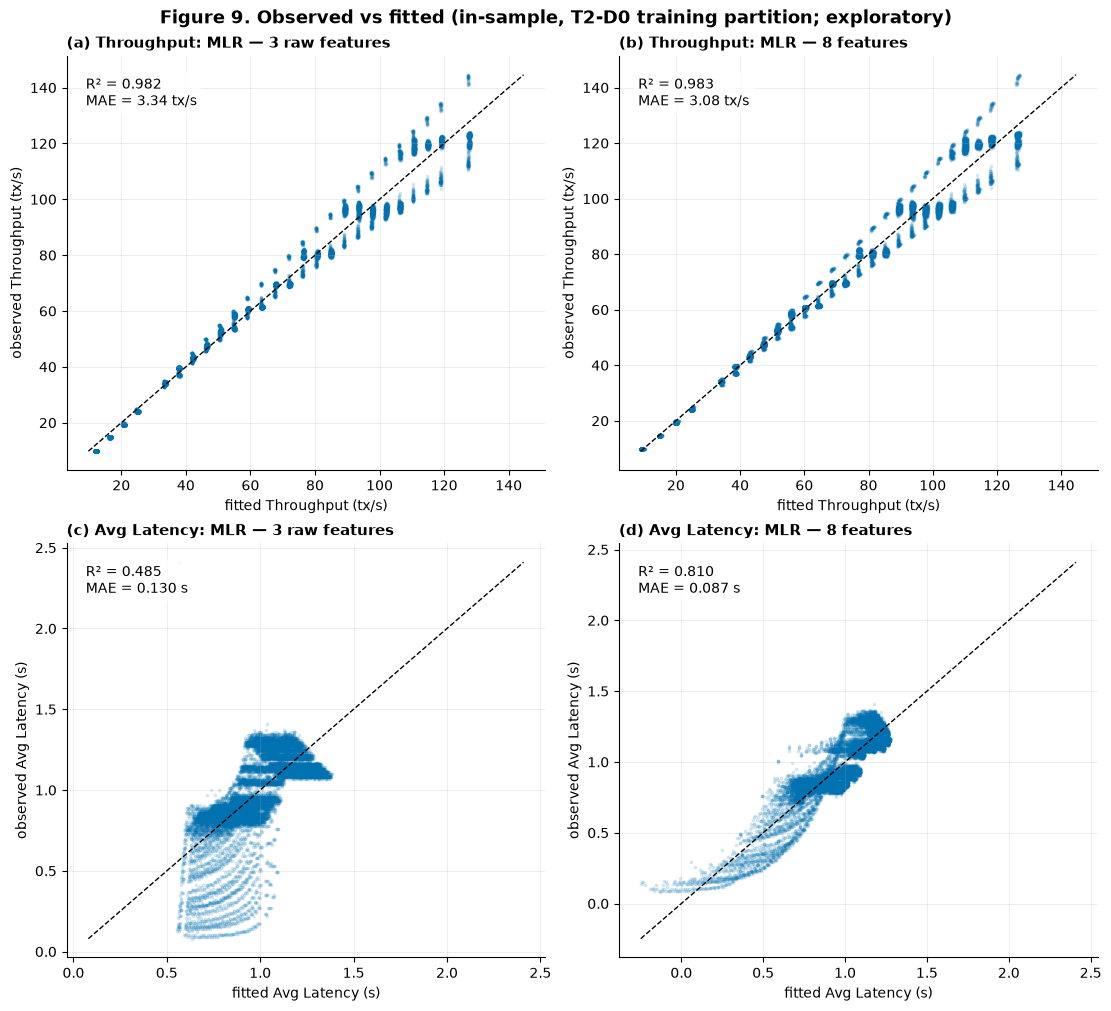

In [18]:
def r2_mae(target, label):
    return r2_score(train[target], fitted[target][label]), mean_absolute_error(train[target], fitted[target][label])


fig, axs = plt.subplots(2, 2, figsize=(11, 10))
fig.suptitle("Figure 9. Observed vs fitted (in-sample, T2-D0 training partition; exploratory)", fontsize=13, fontweight="bold")
for row, target in enumerate((TPUT, LAT)):
    observed_values = train[target].to_numpy()
    for col, label in enumerate((LABEL_3, LABEL_8)):
        ax = axs[row, col]
        ax.scatter(fitted[target][label], observed_values, s=3, alpha=0.12, color=PALETTE["blue"], rasterized=True)
        lims = [min(observed_values.min(), fitted[target][label].min()), max(observed_values.max(), fitted[target][label].max())]
        ax.plot(lims, lims, "k--", lw=1)
        r2, mae = r2_mae(target, label)
        ax.text(0.04, 0.95, f"R² = {r2:.3f}\nMAE = {mae:.{2 if target == TPUT else 3}f} {UNIT[target]}", transform=ax.transAxes, va="top",
                bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.8, "edgecolor": "none"})
        ax.set(xlabel=f"fitted {target} ({UNIT[target]})", ylabel=f"observed {target} ({UNIT[target]})")
        panel(ax, "abcd"[row * 2 + col], f"{target}: {label}")
save_figure(fig, "hfbtp_eda_09_mlr_observed_vs_fitted")

**Reading the figure.** The values quoted come from the printed lines and the table above.

- **(a), (b) Throughput: R² is high, yet the misfit is structured.** The points hug the diagonal, which is why R² is 0.98 for both specifications, but at fitted values above about 90 tx/s the observed values split into a branch above and a branch below the diagonal. The three-feature fit stops at 128.1 tx/s although observed throughput reaches 144.6 tx/s, and it predicts more throughput than was offered in 13.6% of rows, which never happens in the data (no row has throughput above its offered load). The branching is a function of the offered load and the block size jointly, not of the orderer count (Figures 11 and 12 and the residual-structure table below).
- **(c) Latency, three raw features: the small-block rows are missed.** R² is 0.485 and the fitted values never fall below 0.56 s, whereas 5.3% of the training rows are faster than 0.5 s, all of them at block sizes of at most 130 and 86% at 50 or less. They form the fan of points far below the diagonal.
- **(d) Latency, eight features: much better, not right.** R² rises to 0.810 and the fast small-block rows are largely captured, yet the cloud still bends away from the diagonal, and 46 training rows (0.28%) get a negative fitted latency (next bullet).
- **Negative fitted latencies: what the diagnostic is, why it happens and why it matters.** The 46 rows (0.28% of the 16,458 training rows; lowest fitted value −0.25 s) come from the eight-feature specification, a `StandardScaler` followed by `LinearRegression` on the eight engineered features, fitted on the training partition of the registered T2-D0 split. That is the same specification and training partition as the registered `linear` latency model of notebook 03. The printed line above locates the rows at block sizes 10–20 and offered loads of 105–145 tx/s, where the observed latency is small but positive (0.08–0.18 s). Ordinary least squares minimizes squared error and puts no constraint on the sign of its predictions: nothing bounds the linear predictor below by zero, so where the response is small and the fit is not exact it can fall below zero (Figure 9d). The three-feature fit has no negative value (its lowest fitted latency is 0.56 s), but only because it cannot follow the fast rows at all (bullet c). It matters because latency is a positive physical quantity: a negative value cannot be interpreted, can mislead any rule that ranks configurations or compares a predicted latency with a limit, and signals that the linear form is being used where it does not fit. This is an **in-sample diagnostic on the training partition**. It does not show how the model behaves on the validation or test partitions, whose recorded metrics (notebook 03, `experiments/results/hfbtp_baseline_metrics.csv`) this notebook does not touch, and whether negative predictions also occur there was not examined. No clipping, target transformation or refit is applied here; any remedy would change the registered model and is a separate protocol decision.

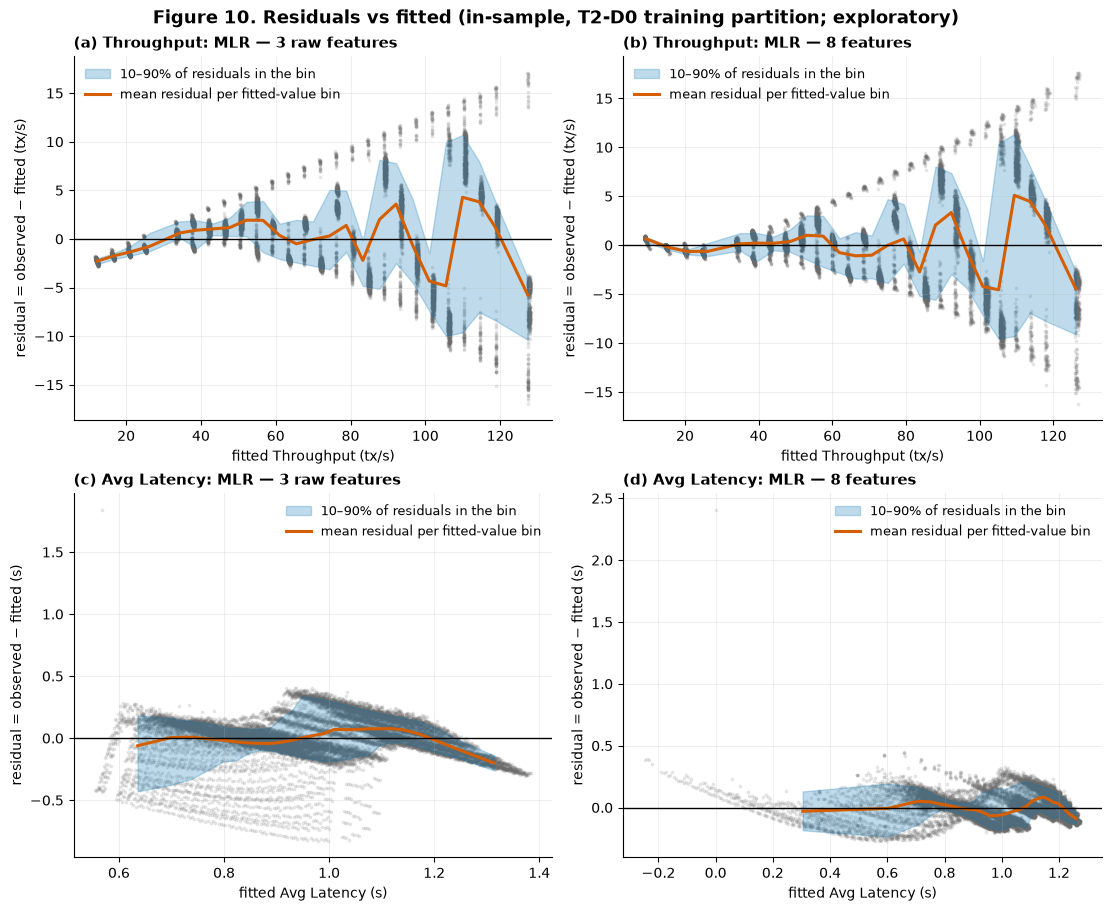

MLR — 3 raw features, Throughput: 10-90% of residuals lie between -5.27 and +5.48 tx/s; smallest and largest residual -17 / +17.1; 10-90% width 3.7 tx/s where the fitted value is below 40 and 19.0 tx/s where it is above 100
MLR — 8 features, Throughput: 10-90% of residuals lie between -5.19 and +5.66 tx/s; smallest and largest residual -16.2 / +17.6; 10-90% width 1.8 tx/s where the fitted value is below 40 and 19.0 tx/s where it is above 100
MLR — 3 raw features, Avg Latency: 10-90% of residuals lie between -0.185 and +0.204 s; smallest and largest residual -0.828 / +1.84
MLR — 8 features, Avg Latency: 10-90% of residuals lie between -0.137 and +0.147 s; smallest and largest residual -0.27 / +2.41
Slowest training row: Avg Latency 2.41 s at offered load 145 tx/s, block size 20, 7 orderers


In [19]:
fig, axs = plt.subplots(2, 2, figsize=(11, 9))
fig.suptitle("Figure 10. Residuals vs fitted (in-sample, T2-D0 training partition; exploratory)", fontsize=13, fontweight="bold")
for row, target in enumerate((TPUT, LAT)):
    for col, label in enumerate((LABEL_3, LABEL_8)):
        ax = axs[row, col]
        fitted_values, resid = fitted[target][label], residual[target][label]
        ax.scatter(fitted_values, resid, s=3, alpha=0.12, color=PALETTE["grey"], rasterized=True)
        bins = pd.qcut(pd.Series(fitted_values), 25, duplicates="drop")
        grouped = pd.DataFrame({"fitted": fitted_values, "residual": resid}).groupby(bins, observed=True)
        trend = pd.DataFrame({"fitted": grouped["fitted"].mean(), "mean": grouped["residual"].mean(),
                              "p10": grouped["residual"].quantile(0.1), "p90": grouped["residual"].quantile(0.9)})
        ax.fill_between(trend["fitted"], trend["p10"], trend["p90"], color=PALETTE["blue"], alpha=0.25, label="10–90% of residuals in the bin")
        ax.plot(trend["fitted"], trend["mean"], color=PALETTE["red"], lw=2.2, label="mean residual per fitted-value bin")
        ax.axhline(0, color="black", lw=1)
        ax.set(xlabel=f"fitted {target} ({UNIT[target]})", ylabel=f"residual = observed − fitted ({UNIT[target]})")
        ax.legend(loc="best")
        panel(ax, "abcd"[row * 2 + col], f"{target}: {label}")
save_figure(fig, "hfbtp_eda_10_mlr_residuals_vs_fitted")

def width_10_90(values):
    return float(np.diff(np.percentile(values, [10, 90]))[0])


for target in (TPUT, LAT):
    for label in (LABEL_3, LABEL_8):
        f, r = fitted[target][label], residual[target][label]
        p10, p90 = np.percentile(r, [10, 90])
        text = f"{label}, {target}: 10-90% of residuals lie between {p10:+.3g} and {p90:+.3g} {UNIT[target]}; smallest and largest residual {r.min():+.3g} / {r.max():+.3g}"
        if target == TPUT:
            text += f"; 10-90% width {width_10_90(r[f < 40]):.1f} tx/s where the fitted value is below 40 and {width_10_90(r[f > 100]):.1f} tx/s where it is above 100"
        print(text)
slowest = train.loc[train[LAT].idxmax()]
print(f"Slowest training row: Avg Latency {slowest[LAT]:.2f} s at offered load {slowest[SET]:g} tx/s, block size {slowest[BLK]:g}, {int(slowest[ORD])} orderers")

**Reading the figure.** For ordinary least squares with an intercept the residuals are uncorrelated with the fitted values by construction, so a flat mean line proves nothing about the fit; what matters is the spread, the banding and the curvature.

- **(a), (b) Throughput:** the residuals fan out as the fitted value grows (printed above: a 10–90% width of about 4 tx/s for fitted values below 40 against about 19 tx/s above 100 for the three-feature fit), and they fall on distinct rays rather than a random cloud. Groups of configurations are therefore systematically above or below the fit. The eight-feature variant narrows the spread at low fitted values (1.8 tx/s) but not at high ones (19.0 tx/s).
- **(c), (d) Latency:** the three-feature residuals include a lower band that reaches −0.8 s, the over-predicted small-block rows, and slope downward at high fitted values. The eight-feature residuals are smaller (printed above) but still curved: positive where the fitted latency is near or below zero, and sloping downward at the highest fitted values. The isolated point at the top of (c) and (d) is the slowest training row (printed above), which neither fit comes close to; its residual is the largest in each panel.

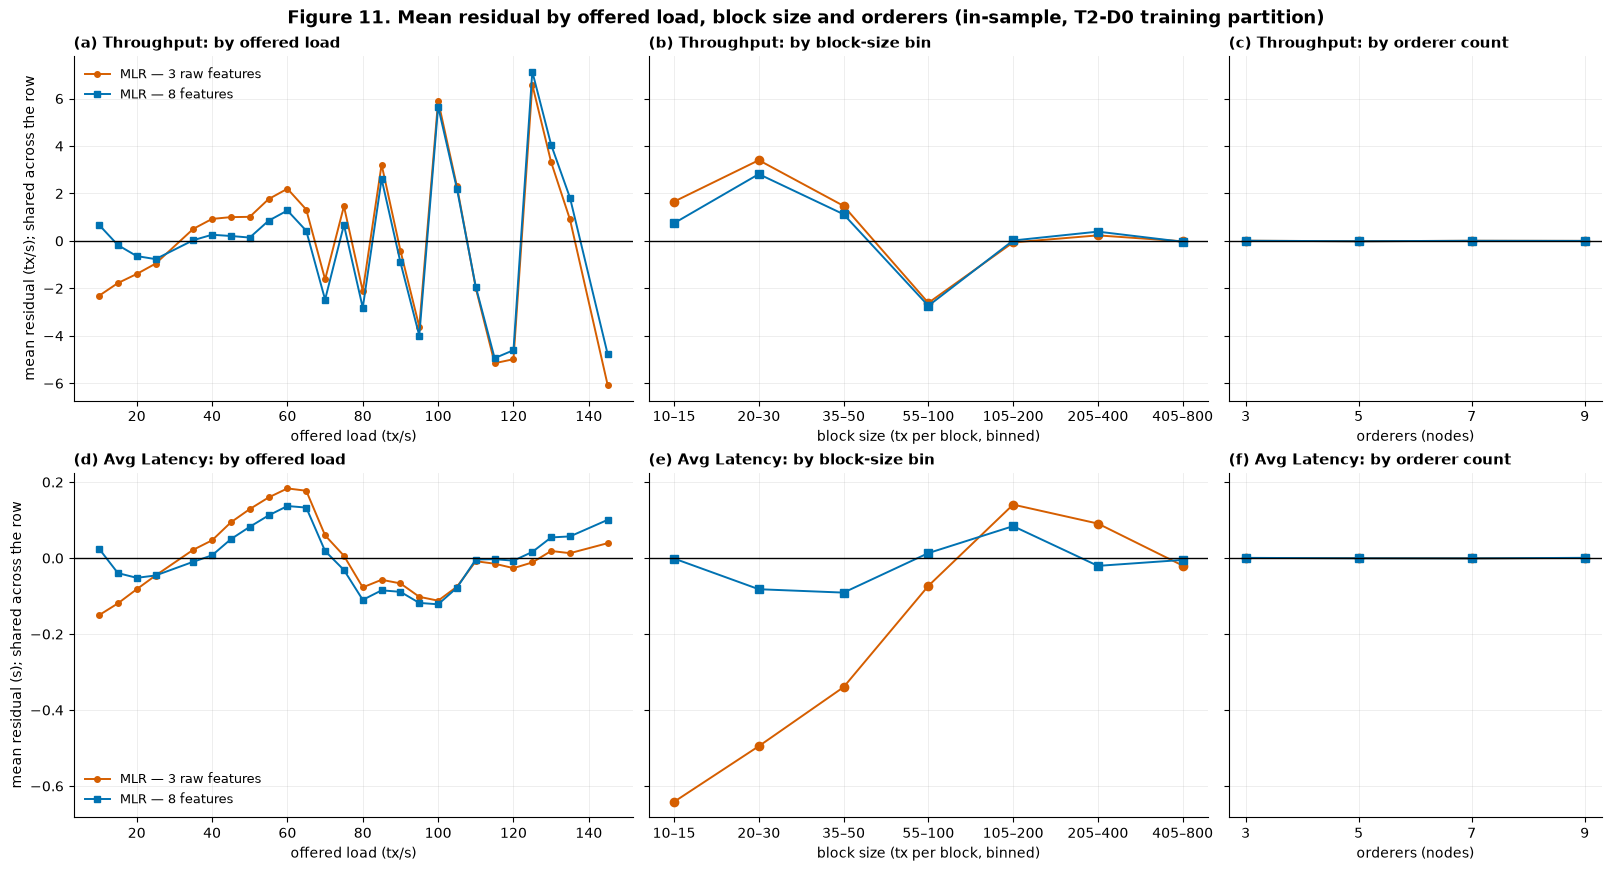

MLR — 3 raw features, Throughput: mean residual by offered load from -6.1 tx/s (at 145) to +6.6 tx/s (at 125); mean |residual| 1.39 tx/s for loads up to 60 and 3.31 tx/s from 70
MLR — 8 features, Throughput: mean residual by offered load from -4.9 tx/s (at 115) to +7.1 tx/s (at 125); mean |residual| 0.50 tx/s for loads up to 60 and 3.37 tx/s from 70
MLR — 3 raw features, Avg Latency: mean residual by offered load from -0.150 s (at 10) to +0.183 s (at 60)
MLR — 8 features, Avg Latency: mean residual by offered load from -0.122 s (at 100) to +0.137 s (at 60)
MLR — 3 raw features, Throughput: mean residual by block-size bin {'10–15': 1.66, '20–30': 3.4, '35–50': 1.48, '55–100': -2.61, '105–200': -0.06, '205–400': 0.23, '405–800': -0.02}
MLR — 8 features, Throughput: mean residual by block-size bin {'10–15': 0.75, '20–30': 2.82, '35–50': 1.12, '55–100': -2.74, '105–200': 0.02, '205–400': 0.39, '405–800': -0.04}
MLR — 3 raw features, Avg Latency: mean residual by block-size bin {'10–15': -0

In [20]:
BLOCK_BIN_EDGES = [0, 15, 30, 50, 100, 200, 400, 800]
BLOCK_BIN_LABELS = ["10–15", "20–30", "35–50", "55–100", "105–200", "205–400", "405–800"]
train["block_bin"] = pd.cut(train[BLK], BLOCK_BIN_EDGES, labels=BLOCK_BIN_LABELS)
LINE_STYLE = {LABEL_3: (PALETTE["red"], "o"), LABEL_8: (PALETTE["blue"], "s")}

fig, axs = plt.subplots(2, 3, figsize=(16, 8.6), gridspec_kw={"width_ratios": [3, 3, 2]}, sharey="row")
fig.suptitle("Figure 11. Mean residual by offered load, block size and orderers (in-sample, T2-D0 training partition)", fontsize=13, fontweight="bold")
for row, target in enumerate((TPUT, LAT)):
    for label, (color, marker) in LINE_STYLE.items():
        resid = pd.Series(residual[target][label], index=train.index)
        by_load = resid.groupby(train[SET]).mean()
        by_bin = resid.groupby(train["block_bin"], observed=True).mean()
        by_orderer = resid.groupby(train[ORD]).mean()
        axs[row, 0].plot(by_load.index, by_load.values, color=color, marker=marker, ms=4, lw=1.4, label=label)
        axs[row, 1].plot(by_bin.index.astype(str), by_bin.values, color=color, marker=marker, ms=6, lw=1.4, label=label)
        axs[row, 2].plot(by_orderer.index.astype(str), by_orderer.values, color=color, marker=marker, ms=6, lw=1.4, label=label)
    for col in range(3):
        axs[row, col].axhline(0, color="black", lw=1)
    axs[row, 0].set_ylabel(f"mean residual ({UNIT[target]}); shared across the row")
    axs[row, 0].legend(loc="best")
    axs[row, 0].set_xlabel("offered load (tx/s)")
    axs[row, 1].set_xlabel("block size (tx per block, binned)")
    axs[row, 2].set_xlabel("orderers (nodes)")
    for col, kind in enumerate(("offered load", "block-size bin", "orderer count")):
        panel(axs[row, col], "abcdef"[row * 3 + col], f"{target}: by {kind}")
save_figure(fig, "hfbtp_eda_11_mlr_residual_patterns")

for label in (LABEL_3, LABEL_8):
    by_load = pd.Series(residual[TPUT][label], index=train.index).groupby(train[SET]).mean()
    print(f"{label}, Throughput: mean residual by offered load from {by_load.min():+.1f} tx/s (at {by_load.idxmin():g}) to {by_load.max():+.1f} tx/s "
          f"(at {by_load.idxmax():g}); mean |residual| {by_load[by_load.index <= 60].abs().mean():.2f} tx/s for loads up to 60 and "
          f"{by_load[by_load.index >= 70].abs().mean():.2f} tx/s from 70")
for label in (LABEL_3, LABEL_8):
    by_load = pd.Series(residual[LAT][label], index=train.index).groupby(train[SET]).mean()
    print(f"{label}, Avg Latency: mean residual by offered load from {by_load.min():+.3f} s (at {by_load.idxmin():g}) to {by_load.max():+.3f} s (at {by_load.idxmax():g})")
for target in (TPUT, LAT):
    for label in (LABEL_3, LABEL_8):
        by_bin = pd.Series(residual[target][label], index=train.index).groupby(train["block_bin"], observed=True).mean()
        print(f"{label}, {target}: mean residual by block-size bin "
              f"{ {name: float(value) for name, value in zip(BLOCK_BIN_LABELS, by_bin.round(2 if target == TPUT else 3))} }")
for target in (TPUT, LAT):
    largest = max(pd.Series(residual[target][label], index=train.index).groupby(train[ORD]).mean().abs().max() for label in (LABEL_3, LABEL_8))
    print(f"{target}: largest mean residual of any orderer count, either fit: {largest:.4f} {UNIT[target]}")

**Reading the figure.** The y-axis is shared within each row, so magnitudes can be compared across the three panels; the quoted values come from the printed lines.

- **By offered load (a, d).** For throughput the mean residual of both fits swings between about −6 and +7 tx/s from 70 tx/s upward: positive where a new ceiling begins (100 and 125 tx/s) and negative where one ends (115–120 and 145 tx/s), the staircase of Section 5 seen from the residual side. The eight-feature variant removes the small low-load bias (mean |residual| 0.5 against 1.4 tx/s up to 60 tx/s) but not the swings from 70 tx/s (3.4 against 3.3 tx/s). For latency both fits under-predict around 60 tx/s (by 0.18 s and 0.14 s, the latency peak of Figure 5c) and over-predict around 80–105 tx/s.
- **By block size (b, e).** In both fits throughput is under-predicted for blocks of 20–30 (by about 3 tx/s) and over-predicted for blocks of 55–100 (by about 2.7 tx/s). For latency the three-feature fit over-predicts the smallest blocks by 0.5–0.64 s and under-predicts blocks of 105–400; the eight-feature variant removes most of that *average* bias (within −0.09 to +0.08 s), though Figure 12 shows it does so partly by averaging errors of opposite sign across loads.
- **By orderers (c, f).** On the shared axis the lines are flat at zero: no first-order orderer pattern remains (the largest mean residual of any orderer count is printed above). This does not exclude a load-conditional orderer effect (Section 6), which a marginal mean cannot show.

Throughput, MLR — 3 raw features: mean |cell-mean residual| 2.63 tx/s; largest -11.2 at offered load 145, block-size bin 55–100


Throughput, MLR — 8 features: mean |cell-mean residual| 2.17 tx/s; largest -9.98 at offered load 145, block-size bin 55–100
Avg Latency, MLR — 3 raw features: mean |cell-mean residual| 0.275 s; largest -0.772 at offered load 40, block-size bin 10–15; 83 of 182 cells lie beyond ±0.2 s
Avg Latency, MLR — 8 features: mean |cell-mean residual| 0.109 s; largest +0.413 at offered load 10, block-size bin 20–30; 29 of 182 cells lie beyond ±0.2 s


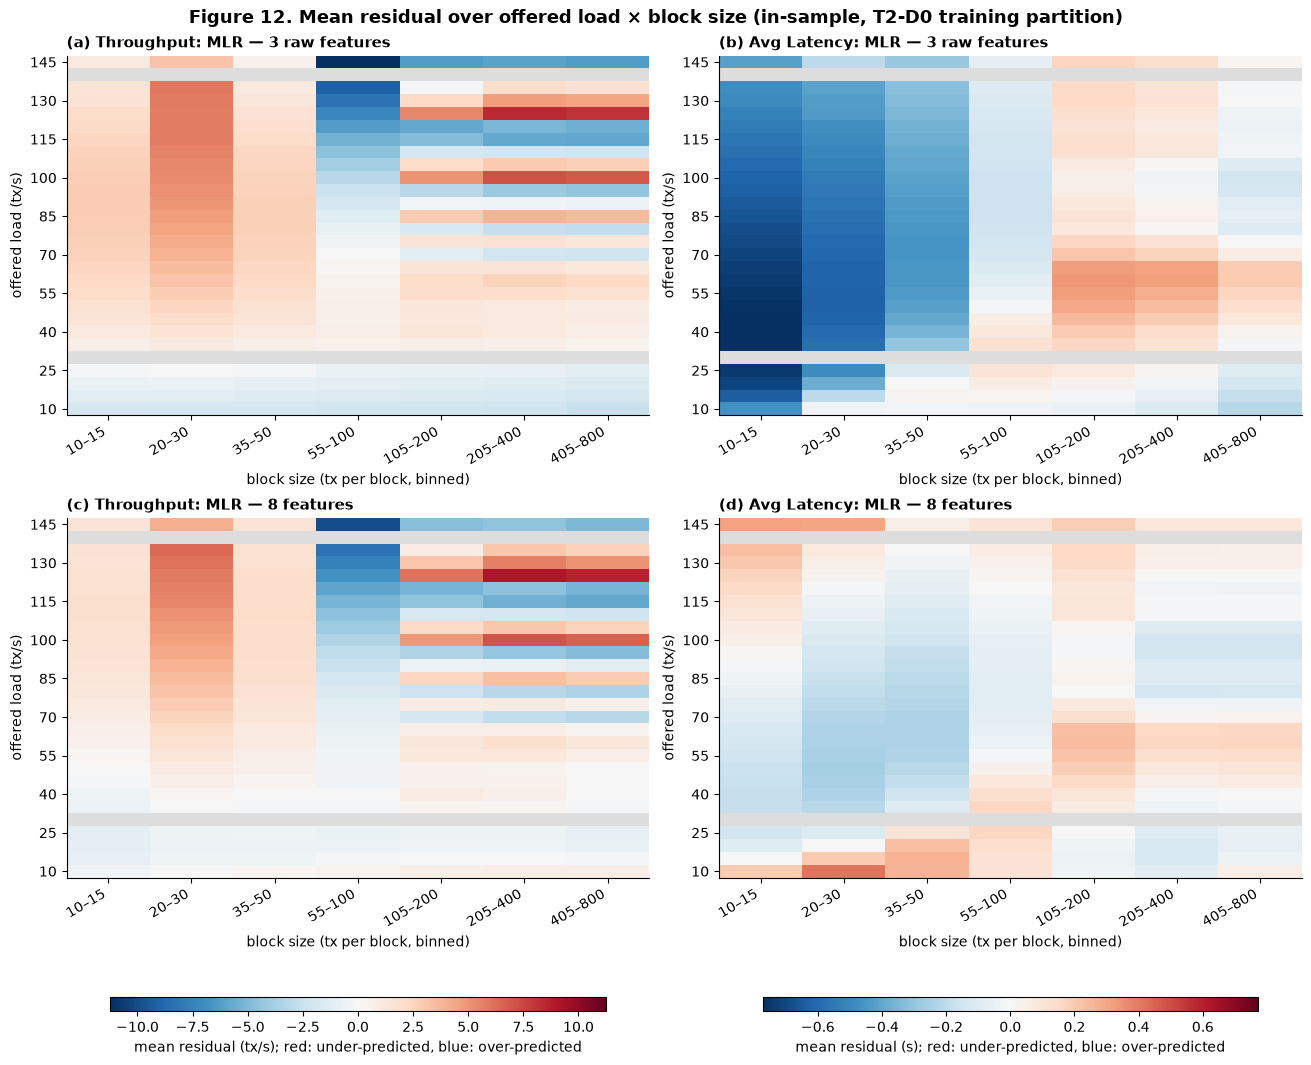

Gray rows are offered-load levels 30, 140: not part of the training partition, no residuals exist.

MLR — 8 features, Avg Latency: mean residual (s) by block-size bin and offered-load range
offered load (tx/s)  10–25  35–100  105–145
block-size bin                             
10–15                -0.01   -0.10     0.17
20–30                 0.13   -0.21     0.03
35–50                 0.22   -0.20    -0.06
55–100                0.13   -0.02     0.01
105–200              -0.03    0.10     0.11
205–400              -0.11   -0.01     0.00
405–800              -0.03   -0.00     0.00


In [21]:
grid_levels = np.arange(train[SET].min(), train[SET].max() + 1, 5)
heatmap_cmap = plt.get_cmap("RdBu_r").copy()
heatmap_cmap.set_bad("#DDDDDD")
fig, axs = plt.subplots(2, 2, figsize=(13, 10.5))
fig.suptitle("Figure 12. Mean residual over offered load × block size (in-sample, T2-D0 training partition)", fontsize=13, fontweight="bold")
for col, target in enumerate((TPUT, LAT)):
    tables = {label: pd.Series(residual[target][label], index=train.index).groupby([train[SET], train["block_bin"]], observed=True)
              .mean().unstack("block_bin").reindex(grid_levels) for label in (LABEL_3, LABEL_8)}
    for label, table in tables.items():
        stacked = table.stack().dropna()
        peak_load, peak_bin = stacked.abs().idxmax()
        beyond = f"; {int((stacked.abs() > 0.2).sum())} of {len(stacked)} cells lie beyond ±0.2 s" if target == LAT else ""
        print(f"{target}, {label}: mean |cell-mean residual| {stacked.abs().mean():.3g} {UNIT[target]}; "
              f"largest {stacked.loc[(peak_load, peak_bin)]:+.3g} at offered load {peak_load:g}, block-size bin {peak_bin}{beyond}")
    limit = max(np.nanmax(np.abs(t.values)) for t in tables.values())
    for row, (label, table) in enumerate(tables.items()):
        ax = axs[row, col]
        image = ax.imshow(np.ma.masked_invalid(table.values), aspect="auto", origin="lower", cmap=heatmap_cmap, vmin=-limit, vmax=limit)
        ax.grid(False)
        ax.set_xticks(range(len(BLOCK_BIN_LABELS)), BLOCK_BIN_LABELS, rotation=30, ha="right")
        ax.set_yticks(range(0, len(grid_levels), 3), [f"{v:g}" for v in grid_levels[::3]])
        ax.set(xlabel="block size (tx per block, binned)", ylabel="offered load (tx/s)")
        panel(ax, "abcd"[row * 2 + col], f"{target}: {label}")
    fig.colorbar(image, ax=axs[:, col], location="bottom", shrink=0.85, aspect=35,
                 label=f"mean residual ({UNIT[target]}); red: under-predicted, blue: over-predicted")
save_figure(fig, "hfbtp_eda_12_mlr_residual_heatmaps")
print(f"Gray rows are offered-load levels {level_ranges(set(grid_levels) - set(train[SET]))}: not part of the training partition, no residuals exist.")

LOAD_RANGES = {"10–25": (10, 25), "35–100": (35, 100), "105–145": (105, 145)}
eight_latency = pd.Series(residual[LAT][LABEL_8], index=train.index)
by_range = pd.DataFrame({name: eight_latency[train[SET].between(low, high)].groupby(train["block_bin"], observed=True).mean()
                         for name, (low, high) in LOAD_RANGES.items()})
by_range.index.name = "block-size bin"
by_range.columns.name = "offered load (tx/s)"
print(f"\n{LABEL_8}, Avg Latency: mean residual (s) by block-size bin and offered-load range")
print(by_range.round(2).to_string())

**Reading the figure.** Each cell averages the residuals of one offered-load level and one block-size bin; gray rows are levels that are not part of the training partition. The color scale is shared by the two models of a target, and the printed lines give the size of the cell averages.

- **Throughput (a, c):** the pattern is two-dimensional and almost identical for the two specifications. Rows of alternating sign for block sizes of 55 and above follow the load staircase, while the sign of whole columns depends on the block-size bin (20–30 is under-predicted at nearly every load from 40 tx/s, 55–100 is over-predicted from 100 tx/s and most strongly at 145 tx/s). The residual depends on the offered load and the block size jointly.
- **Latency (b):** with three raw features, blocks of 10–50 are over-predicted at nearly every load (down to −0.77 s) and blocks of 105–400 are under-predicted, so the bias reverses sign along the block-size axis and changes with load.
- **Latency (d):** the eight-feature variant removes most of that average bias but not the dependence on load. It cuts the typical cell error from 0.275 s to 0.109 s, yet 29 of the 182 cells still lie beyond ±0.2 s. In the 20–50 bins it over-predicts by about 0.2 s at loads of 35–100 tx/s and under-predicts by 0.13–0.22 s at the lowest loads; in the 10–15 bin the residual turns from −0.10 s at 35–100 tx/s to +0.17 s at 105–145 tx/s (table above). What is left depends on load × block size, which the eight-feature form represents only partly.

In [22]:
def share_explained(values, groups):
    """Share of the variation in `values` that a separate mean for every group would explain (eta squared)."""
    values = pd.Series(np.asarray(values), index=groups.index)
    means = values.groupby(groups).transform("mean")
    return float(((means - values.mean()) ** 2).sum() / ((values - values.mean()) ** 2).sum())


cell = train[SET].astype(int).astype(str) + "/" + train[BLK].astype(int).astype(str)
factors = {f"offered load ({train[SET].nunique()} levels)": train[SET],
           f"block size ({train[BLK].nunique()} sizes)": train[BLK],
           f"orderers ({train[ORD].nunique()} counts)": train[ORD],
           f"load × block-size cell ({cell.nunique():,} cells)": cell}
structure = {f"{target}: {label}": {name: share_explained(residual[target][label], groups) for name, groups in factors.items()}
             for target in (TPUT, LAT) for label in (LABEL_3, LABEL_8)}
structure["expected if the residuals were unrelated to the factor"] = {name: (groups.nunique() - 1) / (len(groups) - 1)
                                                                      for name, groups in factors.items()}
residual_structure = pd.DataFrame(structure).T.mul(100).round(1)
residual_structure.columns.name = "% of residual variation explained by a separate mean per:"
residual_structure

% of residual variation explained by a separate mean per:,offered load (26 levels),block size (159 sizes),orderers (4 counts),"load × block-size cell (4,134 cells)"
Throughput: MLR — 3 raw features,47.1,18.6,0.0,90.3
Throughput: MLR — 8 features,44.8,19.3,0.0,89.8
Avg Latency: MLR — 3 raw features,25.6,60.7,0.0,98.2
Avg Latency: MLR — 8 features,47.3,19.4,0.0,95.3
expected if the residuals were unrelated to the factor,0.2,1.0,0.0,25.1


**Reading the table (in-sample, T2-D0 training partition).** Each entry is the share of the residual variation that would be removed by giving every level of the factor its own mean; the last row is what that share would be if the residuals were unrelated to the factor (it only reflects how many groups there are).

- **The leftover error is a function of the two workload inputs, not noise around a good fit.** For both targets and both specifications, a separate mean for every (offered load, block size) cell removes 90–98% of the residual variation, against about 25% expected by chance with this many cells. The offered load alone (45–47% for throughput; 26–47% for latency) or the block size alone (about 19% for throughput; 61% for latency under three features, 19% under eight) each explain a smaller but still far-above-chance share (0.2% and 1.0% expected).
- **The orderer count explains essentially none of it** (0.0%), in line with Section 6 and with Figure 11 (c, f).
- A first-order form, including the eight-feature one, therefore leaves most of its error in a structure that a model flexible in (load, block size) could in principle absorb. This is a statement about *misspecification of the first-order forms on this training partition*; it does not show that any flexible model generalizes better, which only the registered splits can test. The cell means pool the four orderer counts, so the 2–10% that remains unexplained contains orderer-driven differences and run-to-run noise together, and is an upper bound for either.

## 9. Implications for model selection

These are implications of the *observed structure*, stated so that they can be checked later. None of them selects a model, and none changes the protocol: model choice stays governed by `docs/evaluation_protocol.md` (registered splits, validation data only, no test-partition feedback). The last column names the existing protocol element that applies; it does not add a rule.

| Observation in this EDA | Implication for the modeling task | Existing protocol element that applies |
|---|---|---|
| Throughput equals the offered load at low load, then flattens at stepwise ceilings (≈ 96, ≈ 120, ≈ 160 tx/s) | Threshold or piecewise structure is present; a first-order model can only be accurate below the first ceiling | T2/D0 trains only on levels ≤ 145 tx/s; the highest ceiling is reached from 165 tx/s, outside its training range |
| Latency is non-monotone in load, and block size acts in opposite directions at low and high load | Load × block-size interactions matter for latency; one global block-size slope is misleading | All registered splits are reported; no split is dropped after seeing its numbers |
| Above about 130 tx per block the response is nearly flat in block size; below it, it is irregular (Figure 6) | A model can score well on large-block rows without having learned the small-block regime, where the configuration matters most | T1 and T1b hold out only block sizes 210–305 and 710–800, so block-size generalization is never tested in the small-block regime (T2/D0 and T3 do include small blocks in their test rows) |
| Orderer count has almost no marginal effect; where counts differ, it is at a few loads next to the throughput steps, and that cannot be separated from run-to-run noise | A single global orderer coefficient is uninformative; an orderer effect, if any, would need interactions, and the data cannot say whether one exists | T3 orderer transfer is labeled exploratory |
| Offered load alone explains almost all throughput variance (Pearson ≈ 0.98) | R² is inflated; a high score would not show that the configuration knobs are modeled well | MAE (tx/s, s) is the primary metric, RMSE secondary, R² tertiary |
| `Actual` arrival rate equals the set rate almost exactly but is measured during the run | Using it would leak run state into the prediction | Forbidden feature |
| Design variables are regular 5-unit grids, one observation per cell, no replication | Random row splits would put neighboring cells on both sides of a split; there is no noise floor to calibrate errors against | Registered grouped splits (T1, T1b, T2/D0, T3); no claim about run-to-run variability |
| Residuals of the first-order models are structured (Section 8) | Multiple Linear Regression is an informative first-order reference. The EDA gives no basis to expect it to handle interactions or thresholds, but which model is best must be decided on validation data under the registered splits, not from this EDA | Models may not use test-partition feedback for revision |

## 10. Limitations and transition to modeling

**What this EDA cannot support**

- **Run-to-run variability, uncertainty or significance.** One observation per cell: no noise floor, no replicates, no confidence intervals.
- **Causal claims.** Every statement is an association within one historical campaign.
- **Temporal claims.** There are no timestamps; row order is design order. The data are a static response surface, not a time series, so reaction speed, recovery and closed-loop behavior are out of reach.
- **Generality.** A single environment and workload type; provenance is inherited from documentation, not verifiable from the CSV. Cell independence is not experiment independence: all rows share one deployment and campaign.
- **Anything about the 117 absent cells.** They are never imputed, and the reason for their absence is unknown.
- **Physically valid predictions from the linear baselines.** Ordinary least squares places no bounds on its output; the eight-feature fit returns negative latencies for 46 training rows (Section 8). That is an in-sample finding, not evidence about validation or test accuracy, and no correction is applied here.
- **Independence of the descriptive analysis from the held-out data.** Sections 2–7 describe all 24,687 rows, including rows that later serve as test partitions in the registered splits, and those test partitions have already been inspected repeatedly. They are treated as exposed: this EDA is not used for selection, and any future selection must rely on validation data or on grouped cross-validation inside training partitions.

**Transition.** The registered baseline run, with the registered splits and the metrics hierarchy, is in `03_hfbtp_baseline_model.ipynb`; the audit that pins the file identity is in `01_dataset_audit.ipynb`. The exploratory regressions of Section 8 are diagnostics only and do not replace or repeat that run.

In [23]:
corr_p, corr_s = correlations["Pearson (linear)"], correlations["Spearman (rank, monotone)"]
summary = {
    "dataset": {"rows": int(len(df)), "columns": int(df.shape[1]),
                "md5_matches_manifest": bool(identity.loc["MD5", "match"]),
                "sha256_matches_manifest": bool(identity.loc["SHA-256", "match"])},
    "grid": {k: (float(v) if isinstance(v, float) else int(v)) for k, v in grid["computed from file"].items()},
    "grid_matches_manifest": bool(grid["match"].all()),
    "quality_flags": {k: int(v) for k, v in quality.iloc[:, 0].items()},
    "distribution": {c: {"skew": round(float(df[c].skew()), 3), "excess_kurtosis": round(float(df[c].kurt()), 3)} for c in (TPUT, LAT)},
    "correlation_pearson": corr_p.round(3).to_dict(),
    "correlation_spearman": corr_s.round(3).to_dict(),
    "corr_actual_vs_set_rate": round(float(df[ACT].corr(df[SET])), 5),
    "median_throughput_by_offered_load": {f"{v}": round(float(tput_q.loc[v, 0.5]), 1) for v in (100, 120, 130, 160, 165, 180, 200)},
    "orderer_throughput_spread": {
        "bands_tx_per_s": list(band_spread),
        "median_spread": [round(float(s.median()), 2) for s in band_spread.values()],
        "share_above_10_tx_per_s_pct": [round(float((s > LARGE_SPREAD).mean() * 100), 1) for s in band_spread.values()],
        "groups_above_10_tx_per_s_by_offered_load": {f"{load:g}": int(count) for load, count in groups_by_load.sort_index().items()},
    },
    "residual_structure_pct_explained": residual_structure.to_dict(orient="index"),
    "block_size_plateau": interaction_table.to_dict(),
    "mlr_in_sample_exploratory": {
        "partition": "T2-D0 training rows only (validation and test never used)",
        "rows": int(len(train)),
        "negative_fitted_avg_latency_rows": {label: int((fitted[LAT][label] < 0).sum()) for label in (LABEL_3, LABEL_8)},
        "metrics": ladder.round(4).to_dict(orient="index"),
    },
    "figures": FIGURES,
    "interpretation_note": ("Descriptive associations on one observation per configuration cell; no replication, no timestamps; "
                            "no causal or temporal inference. Exploratory fits are in-sample diagnostics, not registered results."),
}
summary_path = RES / "hfbtp_eda_summary.json"
save_json(summary, summary_path)
print(f"saved: experiments/results/{summary_path.name}")
print("figures:", ", ".join(FIGURES))

saved: experiments/results/hfbtp_eda_summary.json
figures: hfbtp_eda_01_data_quality.png, hfbtp_eda_02_suspicious_values.png, hfbtp_eda_03_design_variables.png, hfbtp_eda_04_outcome_distributions.png, hfbtp_eda_05_workload_performance.png, hfbtp_eda_06_load_block_interaction.png, hfbtp_eda_07_orderer_effect.png, hfbtp_eda_08_correlation.png, hfbtp_eda_09_mlr_observed_vs_fitted.png, hfbtp_eda_10_mlr_residuals_vs_fitted.png, hfbtp_eda_11_mlr_residual_patterns.png, hfbtp_eda_12_mlr_residual_heatmaps.png
